In [ ]:
import cmath
import math
import random

import marimo as mo
import sympy as sp

def Eqn(lhs, rhs):
    """Equation shown as written: lhs = rhs, never evaluated to True."""
    return sp.Eq(lhs, rhs, evaluate=False)

class key:
    """Marks a central result: step() draws a frame around it."""

    def __init__(self, eq):
        self.eq = eq

class new:
    """Marks a new symbol, definition or substitution (an equation, or a LaTeX string): highlighted in blue."""

    def __init__(self, eq):
        self.eq = eq

# frame drawn with CSS around the rendered formula (KaTeX's \boxed collapses in marimo's output)
_frame = {
    "border": "1.5px solid currentColor",
    "border-radius": "4px",
    "padding": "0 1.2em",
    "margin": "0.5em auto",
    "width": "fit-content",
    "max-width": "100%",
    "overflow-x": "auto",
}
# tint for new symbols / substitutions (readable in light and dark mode)
_tint = {
    "background": "rgba(37, 99, 235, 0.10)",
    "border-left": "4px solid rgb(37, 99, 235)",
    "border-radius": "4px",
    "padding": "0 1.2em",
    "margin": "0.5em auto",
    "width": "fit-content",
    "max-width": "100%",
    "overflow-x": "auto",
}

def step(text, *eqs, order=None):
    """Render a step description followed by one or more equations.

    order="none" prints products and sums in the order they were built (use with evaluate=False).
    Equations wrapped in key(...) are framed: the central results to remember.
    """
    parts, plain = [], []

    def flush():
        if plain:
            parts.append(mo.md("\n\n".join(plain)))
            plain.clear()

    for e in eqs:
        style = {}
        if isinstance(e, key):
            style = {**style, **_frame}
            e = e.eq
        if isinstance(e, new):
            style = {**style, **_tint}
            e = e.eq
        tex = e if isinstance(e, str) else sp.latex(e, order=order)
        if style:
            flush()
            parts.append(mo.md(f"$$ {tex} $$").style(style))
        else:
            plain.append(f"$$ {tex} $$")
    flush()
    return mo.vstack([mo.md(text), *parts], gap=0.25)

def lin(e, M=None, M_val=3):
    """Normal form for linearity checks: expand sums (M -> M_val), split integrals over terms, pull out constants."""
    if M is not None:
        e = e.replace(lambda z: isinstance(z, sp.Sum), lambda z: z.subs(M, M_val).doit(deep=False))
    if isinstance(e, sp.Integral):
        f = e.function
        for lim in e.limits:  # innermost first
            out = 0
            for term in sp.Add.make_args(sp.expand(lin(f))):
                c, d = term.as_independent(lim[0], as_Add=False)
                out += c * sp.Integral(d, lim)
            f = out
        return f
    if e.args and not isinstance(e, (sp.Indexed, sp.Symbol)):
        return e.func(*[lin(a) for a in e.args])
    return e

def check(new, old, M=None):
    """SymPy check of one step: new - old in linearity normal form (0 means the step is correct)."""
    return Eqn(sp.Symbol(r"\text{difference}"), sp.expand(lin(new, M) - lin(old, M)))

def diff0(new, old):
    """SymPy check of one step: simplified new - old (0 means the step is correct)."""
    return Eqn(sp.Symbol(r"\text{difference}"), sp.simplify(new - old))

def mul(*f):
    """Product kept in reading order."""
    return sp.Mul(*f, evaluate=False)

def add(*a):
    """Sum kept in reading order."""
    return sp.Add(*a, evaluate=False)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Example for all plots: the resonator of the BLonD near-/far-field note, R_s = 1 Ohm, f_r = 0.7 GHz,
# Q = 11, binned with dt = 1 ns. Time is measured in bins (t / dt), the wake is normalised to W(0+) = 1.
_wr = 2 * np.pi * 0.7e9
_alpha = _wr / (2 * 11.0)
_wbar = np.sqrt(_wr**2 - _alpha**2)
ex_sig = complex(-_alpha, _wbar) * 1e-9  # sigma_p = s_p dt
ex_r = 0.5 * complex(1.0, _alpha / _wbar)  # residue, scaled so that W(0+) = 2 Re r = 1

def f_h(t):
    """Bin kernel h (times dt), with the half values at the edges."""
    t = np.abs(np.asarray(t, dtype=float))
    return np.where(t < 0.5, 1.0, np.where(t == 0.5, 0.5, 0.0))

def f_hat(t):
    return np.maximum(0.0, 1.0 - np.abs(np.asarray(t, dtype=float)))

def f_b2(t):
    t = np.abs(np.asarray(t, dtype=float))
    return np.where(t <= 0.5, 0.75 - t**2, np.where(t <= 1.5, 0.5 * (1.5 - t) ** 2, 0.0))

def f_E(xx):
    """E(x) = e^x - 1 - x - x^2/2, by its series near 0 (no cancellation)."""
    xx = np.asarray(xx, dtype=complex)
    series = sum(xx**m / math_factorial(m) for m in range(3, 16))
    return np.where(np.abs(xx) < 0.5, series, np.exp(xx) - 1 - xx - xx**2 / 2)

def math_factorial(m):
    out = 1
    for i_ in range(2, m + 1):
        out *= i_
    return out

def f_W(t):
    """Pole-residue wake (one conjugate pair), theta(0) = 1/2."""
    t = np.asarray(t, dtype=float)
    w = 2 * np.real(ex_r * np.exp(ex_sig * t))
    return np.where(t > 0, w, np.where(t == 0, 0.5 * w, 0.0))

def f_G(t):
    t = np.asarray(t, dtype=float)
    return np.where(t > 0, f_E(ex_sig * t) / ex_sig**3, 0.0)

def f_Wt(t):
    """Effective wake W~ = h*h*h*W: third difference of G (Step 51), far form for t > 3/2 (Step 57)."""
    t = np.asarray(t, dtype=float)
    near = 2 * np.real(ex_r * (f_G(t + 1.5) - 3 * f_G(t + 0.5) + 3 * f_G(t - 0.5) - f_G(t - 1.5)))
    far = 2 * np.real(ex_r * ((np.exp(ex_sig) - 1) / ex_sig) ** 3 * np.exp(ex_sig * (t - 1.5)))
    return np.where(t > 1.5, far, near)

def f_far(t):
    """Far-field formula of Step 57, continued to every t."""
    t = np.asarray(t, dtype=float)
    return 2 * np.real(ex_r * ((np.exp(ex_sig) - 1) / ex_sig) ** 3 * np.exp(ex_sig * (t - 1.5)))

# Induced voltage from a wakefield — the short way

The conventions are chosen up front so that
almost no substitutions or identities are needed on the way:

1. **One time variable.** $t$ is time everywhere, $t'$ the integration variable.
   Every integral is a convolution $(f * g)(t) = \int f(t - t')\, g(t')\, dt'$, and we use its
   algebra (linear, commutative, associative, shift) instead of renaming variables.
2. **Bin-centred grid.** Bin centres $t_\ell = \ell\,\Delta t$: the origin sits on a bin centre
   ($t_0$ always cancelled anyway).
3. **Bin kernel from steps.** The box is the difference of two Heaviside steps at the bin
   edges, centred and normalised: $h = \delta\theta / \Delta t$. It is even, so the bin
   average is a convolution evaluated at the bin centre (no flip).
4. **Two tools do all the work.** The central difference $\delta$ commutes with convolution,
   and $\theta * g$ is the running integral of $g$. So every box is one difference and one
   integration: hat, causal cut, near and far field all fall out of this.
5. **One complex pole term.** Carry only $\theta(t)\, e^{s_p t}$ and take $2\,\mathrm{Re}$ at the end.
6. **Pole in bins.** $\sigma_p = s_p\,\Delta t$ is not introduced by hand: it appears by itself
   when we evaluate on the grid.

**Reading aid.** A **frame** marks a result to remember. A **blue bar** marks a new symbol, definition or substitution.

Symbols:

- $W(t)$: wake function (V/C), $\lambda(t)$: line density with $\int \lambda\, dt = 1$
- $q$: particle charge, $N$: number of particles, $\Delta t$: bin width
- $\theta(t)$: Heaviside step with $\theta(0) = \tfrac12$

In [ ]:
t, tp = sp.symbols("t t'", real=True)
a = sp.Symbol("a", real=True)
dt = sp.Symbol(r"\Delta t", positive=True)
q, N = sp.symbols("q N", positive=True)
W = sp.Function("W")
lam = sp.Function("lambda")
V_ind = sp.Function(r"V_{\mathrm{ind}}")
f = sp.Function("f")
g = sp.Function("g")
theta = sp.Heaviside

def delta(expr, k=1):
    """Central difference in t, applied k times: f(t + dt/2) - f(t - dt/2)."""
    for _ in range(k):
        expr = expr.subs(t, t + dt / 2) - expr.subs(t, t - dt / 2)
    return expr

In [ ]:
WL = sp.Function(r"\left(W * \lambda\right)")
eq1 = Eqn(V_ind(t), -q * N * WL(t))
step(
    r"**Step 1.** Induced voltage: the wake function convolved with the line density.",
    key(eq1),
    new(Eqn(WL(t), sp.Integral(W(t - tp) * lam(tp), (tp, -sp.oo, sp.oo)))),
)

Step 1. Induced voltage: the wake function convolved with the line density. \[ V_{\mathrm{ind}}{\left(t \right)} = - N q \left(W * \lambda\right){\left(t \right)} \] \[ \left(W * \lambda\right){\left(t \right)} = \int\limits_{-\infty}^{\infty} W{\left(t - t' \right)} \lambda{\left(t' \right)}\, dt' \]

## 1. Two tools

In [ ]:
fg = sp.Function(r"\left(f * g\right)")
eq2 = Eqn(fg(t), sp.Integral(f(t - tp) * g(tp), (tp, -sp.oo, sp.oo)))
step(r"**Step 2.** Convolution. It is linear, commutative and associative.", new(eq2))

Step 2. Convolution. It is linear, commutative and associative. \[ \left(f * g\right){\left(t \right)} = \int\limits_{-\infty}^{\infty} f{\left(t - t' \right)} g{\left(t' \right)}\, dt' \]

In [ ]:
df = sp.Function(r"\left(\delta f\right)")
eq3 = Eqn(df(t), f(t + dt / 2) - f(t - dt / 2))
step(
    r"**Step 3.** Central difference over one bin width: value at the right bin edge minus value at the left one.",
    new(eq3),
)

Step 3. Central difference over one bin width: value at the right bin edge minus value at the left one. \[ \left(\delta f\right){\left(t \right)} = - f{\left(- \frac{\Delta t}{2} + t \right)} + f{\left(\frac{\Delta t}{2} + t \right)} \]

In [ ]:
dfg = sp.Function(r"\left(\delta f * g\right)")
eq4 = Eqn(dfg(t), sp.Integral(eq3.rhs.subs(t, t - tp) * g(tp), (tp, -sp.oo, sp.oo)))
step(r"**Step 4.** Convolve $\delta f$ with $g$: Step 2 with Step 3 inserted at $t - t'$.", eq4)

Step 4. Convolve \(\delta f\) with \(g\): Step 2 with Step 3 inserted at \(t - t'\). \[ \left(\delta f * g\right){\left(t \right)} = \int\limits_{-\infty}^{\infty} \left(- f{\left(- \frac{\Delta t}{2} + t - t' \right)} + f{\left(\frac{\Delta t}{2} + t - t' \right)}\right) g{\left(t' \right)}\, dt' \]

In [ ]:
eq5 = Eqn(
    dfg(t),
    sp.Integral(f(t + dt / 2 - tp) * g(tp), (tp, -sp.oo, sp.oo))
    - sp.Integral(f(t - dt / 2 - tp) * g(tp), (tp, -sp.oo, sp.oo)),
)
step(
    r"**Step 5.** Split the integral of the difference into two integrals."
    "\n\n*Check: this step minus the previous one:*",
    eq5,
    check(eq5.rhs, eq4.rhs),
)

Step 5. Split the integral of the difference into two integrals. 
 Check: this step minus the previous one: \[ \left(\delta f * g\right){\left(t \right)} = - \int\limits_{-\infty}^{\infty} f{\left(- \frac{\Delta t}{2} + t - t' \right)} g{\left(t' \right)}\, dt' + \int\limits_{-\infty}^{\infty} f{\left(\frac{\Delta t}{2} + t - t' \right)} g{\left(t' \right)}\, dt' \]\[ \text{difference} = 0 \]

In [ ]:
eq6 = Eqn(dfg(t), fg(t + dt / 2) - fg(t - dt / 2))
dfg2 = sp.Function(r"\delta\left(f * g\right)")
step(
    r"**Step 6.** Each integral is Step 2 at a shifted time, $t \pm \tfrac{\Delta t}{2}$. "
    r"So $\delta$ can be moved out of a convolution, from any of its factors "
    r"(convolution is commutative):"
    "\n\n*Check: Step 2 at the shifted times minus Step 5:*",
    eq6,
    key(Eqn(dfg(t), dfg2(t))),
    diff0(eq2.rhs.subs(t, t + dt / 2) - eq2.rhs.subs(t, t - dt / 2), eq5.rhs),
)

Step 6. Each integral is Step 2 at a shifted time, \(t \pm \tfrac{\Delta t}{2}\). So \(\delta\) can be moved out of a convolution, from any of its factors (convolution is commutative): 
 Check: Step 2 at the shifted times minus Step 5: \[ \left(\delta f * g\right){\left(t \right)} = - \left(f * g\right){\left(- \frac{\Delta t}{2} + t \right)} + \left(f * g\right){\left(\frac{\Delta t}{2} + t \right)} \] \[ \left(\delta f * g\right){\left(t \right)} = \delta\left(f * g\right){\left(t \right)} \] \[ \text{difference} = 0 \]

In [ ]:
thg = sp.Function(r"\left(\theta * g\right)")
eq7 = Eqn(thg(t), sp.Integral(theta(t - tp) * g(tp), (tp, -sp.oo, sp.oo)))
step(r"**Step 7.** Convolve the step $\theta$ with $g$ (Step 2).", eq7)

Step 7. Convolve the step \(\theta\) with \(g\) (Step 2). \[ \left(\theta * g\right){\left(t \right)} = \int\limits_{-\infty}^{\infty} g{\left(t' \right)} \theta\left(t - t'\right)\, dt' \]

In [ ]:
eq8 = Eqn(thg(t), sp.Integral(g(tp), (tp, -sp.oo, t)))
_test = eq7.rhs.xreplace({g(tp): sp.exp(tp)})
step(
    r"**Step 8.** $\theta(t - t') = 1$ for $t' < t$ and $0$ for $t' > t$: convolving with the step "
    r"is the **running integral**."
    "\n\n*Check with the test function $g(t') = e^{t'}$: the integral of Step 7 is*",
    key(eq8),
    Eqn(_test, _test.doit()),
)

Step 8. \(\theta(t - t') = 1\) for \(t' < t\) and \(0\) for \(t' > t\): convolving with the step is the running integral . 
 Check with the test function \(g(t') = e^{t'}\): the integral of Step 7 is \[ \left(\theta * g\right){\left(t \right)} = \int\limits_{-\infty}^{t} g{\left(t' \right)}\, dt' \] \[ \int\limits_{-\infty}^{\infty} e^{t'} \theta\left(t - t'\right)\, dt' = e^{t} \]

In [ ]:
eq9 = Eqn(thg(t), theta(t) * sp.Integral(g(tp), (tp, 0, t)))
_gc = theta(tp) * sp.exp(-tp)  # causal test function
_ok = all(
    sp.simplify(sp.integrate(_gc, (tp, -sp.oo, v)) - (theta(v) * sp.integrate(_gc, (tp, 0, v)))) == 0
    for v in [-2, -1, 1, 2]
)
step(
    r"**Step 9.** If $g$ is causal ($g(t') = 0$ for $t' < 0$): nothing below $0$ contributes, and for "
    r"$t < 0$ nothing at all."
    "\n\n*Check with $g(t') = \\theta(t')\\, e^{-t'}$ against Step 8 at $t = -2, -1, 1, 2$:* " + f"**{_ok}**",
    eq9,
)

Step 9. If \(g\) is causal (\(g(t') = 0\) for \(t' < 0\)): nothing below \(0\) contributes, and for \(t < 0\) nothing at all. 
 Check with \(g(t') = \theta(t')\, e^{-t'}\) against Step 8 at \(t = -2, -1, 1, 2\): True \[ \left(\theta * g\right){\left(t \right)} = \theta\left(t\right) \int\limits_{0}^{t} g{\left(t' \right)}\, dt' \]

In [ ]:
fga = sp.Function(r"\left(f * g(\cdot - a)\right)")
eq10 = Eqn(fga(t), sp.Integral(f(t - tp) * g(tp - a), (tp, -sp.oo, sp.oo)))
step(r"**Step 10.** Convolve with a shifted function $g(t - a)$ (Step 2).", new(eq10))

Step 10. Convolve with a shifted function \(g(t - a)\) (Step 2). \[ \left(f * g(\cdot - a)\right){\left(t \right)} = \int\limits_{-\infty}^{\infty} f{\left(t - t' \right)} g{\left(- a + t' \right)}\, dt' \]

In [ ]:
eq11 = Eqn(fga(t), sp.Integral(f(t - a - tp) * g(tp), (tp, -sp.oo, sp.oo)))
# check of the shift t' -> t' + a with Gaussian test functions
_tf = lambda e: e.replace(f, sp.Lambda(tp, sp.exp(-tp**2))).replace(g, sp.Lambda(tp, tp * sp.exp(-2 * tp**2)))
_d = sp.simplify(_tf(eq11.rhs).doit() - _tf(eq10.rhs).doit())
step(
    r"**Step 11.** Shift the integration variable, $t' \to t' + a$ (limits stay $\pm\infty$)."
    "\n\n*Check with $f = e^{-t^2}$, $g = t\\, e^{-2t^2}$: this step minus the previous one:*",
    new(r"t' \to t' + a"),
    eq11,
    Eqn(sp.Symbol(r"\text{difference}"), _d),
)

Step 11. Shift the integration variable, \(t' \to t' + a\) (limits stay \(\pm\infty\)). 
 Check with \(f = e^{-t^2}\), \(g = t\, e^{-2t^2}\): this step minus the previous one: \[ t' \to t' + a \] \[ \left(f * g(\cdot - a)\right){\left(t \right)} = \int\limits_{-\infty}^{\infty} f{\left(- a + t - t' \right)} g{\left(t' \right)}\, dt' \]\[ \text{difference} = 0 \]

In [ ]:
step(
    r"**Step 12.** That is Step 2 at $t - a$: shifting a factor shifts the convolution."
    "\n\n*Check: Step 2 at t − a minus Step 11:*",
    Eqn(fga(t), fg(t - a)),
    diff0(eq2.rhs.subs(t, t - a), eq11.rhs),
)

Step 12. That is Step 2 at \(t - a\): shifting a factor shifts the convolution. 
 Check: Step 2 at t − a minus Step 11: \[ \left(f * g(\cdot - a)\right){\left(t \right)} = \left(f * g\right){\left(- a + t \right)} \]\[ \text{difference} = 0 \]

## 2. The bin kernel and the bin voltage

In [ ]:
h = sp.Function("h")
dth = sp.Function(r"\left(\delta\theta\right)")
h_def = (theta(t + dt / 2) - theta(t - dt / 2)) / dt
eq13 = Eqn(h(t), h_def)
step(
    r"**Step 13.** Bin kernel: a step up at the left bin edge, a step down at the right one, "
    r"height $\frac{1}{\Delta t}$. By Step 3 this is a central difference of the step:",
    new(eq13),
    key(Eqn(h(t), dth(t) / dt)),
)

Step 13. Bin kernel: a step up at the left bin edge, a step down at the right one, height \(\frac{1}{\Delta t}\). By Step 3 this is a central difference of the step: \[ h{\left(t \right)} = \frac{- \theta\left(- \frac{\Delta t}{2} + t\right) + \theta\left(\frac{\Delta t}{2} + t\right)}{\Delta t} \] \[ h{\left(t \right)} = \frac{\left(\delta\theta\right){\left(t \right)}}{\Delta t} \]

In [ ]:
# the three cases written by hand (SymPy's own Piecewise rewrite of the two steps is unreadable)
_h_cases = sp.Piecewise(
    (1 / dt, sp.Abs(t) < dt / 2),
    (1 / (2 * dt), sp.Eq(sp.Abs(t), dt / 2)),
    (0, True),
)
_area = sp.Integral(h(t), (t, -sp.oo, sp.oo))
_pts = [sp.Rational(k, 4) * dt for k in range(-6, 7)]
_cases_ok = all(sp.simplify(h_def.subs(t, v) - _h_cases.subs(t, v)) == 0 for v in _pts)
_even = all(sp.simplify(h_def.subs(t, -v) - h_def.subs(t, v)) == 0 for v in _pts)
step(
    r"**Step 14.** Properties: $\frac{1}{\Delta t}$ inside the bin, $0$ outside, half height on the two edges "
    r"(because $\theta(0) = \tfrac12$), unit area, and even, $h(-t) = h(t)$ "
    r"(since $\theta(-x) = 1 - \theta(x)$)."
    "\n\n*Checks at $t = k\\,\\Delta t / 4$, $|k| \\le 6$ (edges included): the cases agree with Step 13: "
    + f"**{_cases_ok}**; even: **{_even}**. Area by SymPy:*",
    Eqn(h(t), _h_cases),
    Eqn(_area, sp.integrate(_h_cases, (t, -sp.oo, sp.oo))),
)

Step 14. Properties: \(\frac{1}{\Delta t}\) inside the bin, \(0\) outside, half height on the two edges (because \(\theta(0) = \tfrac12\)), unit area, and even, \(h(-t) = h(t)\) (since \(\theta(-x) = 1 - \theta(x)\)). 
 Checks at \(t = k\,\Delta t / 4\), \(|k| \le 6\) (edges included): the cases agree with Step 13: True ; even: True . Area by SymPy: \[ h{\left(t \right)} = \begin{cases} \frac{1}{\Delta t} & \text{for}\: \left|{t}\right| < \frac{\Delta t}{2} \\\frac{1}{2 \Delta t} & \text{for}\: \left|{t}\right| = \frac{\Delta t}{2} \\0 & \text{otherwise} \end{cases} \]\[ \int\limits_{-\infty}^{\infty} h{\left(t \right)}\, dt = 1 \]

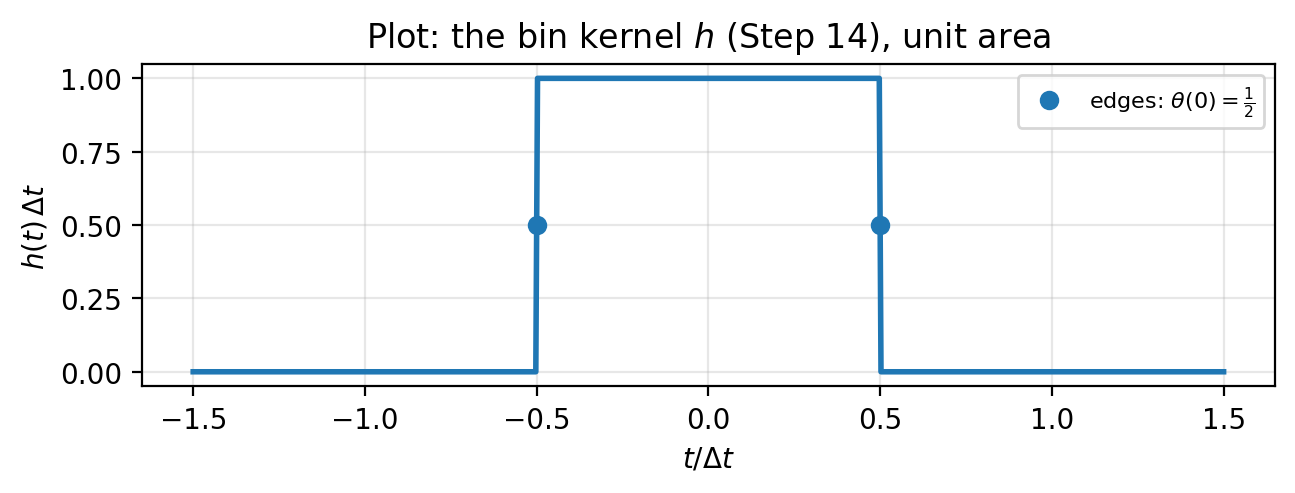

In [ ]:
_t = np.linspace(-1.5, 1.5, 1201)
_fig, _ax = plt.subplots(figsize=(6.5, 2.6))
_ax.plot(_t, f_h(_t), lw=2)
_ax.plot([-0.5, 0.5], [0.5, 0.5], "o", color="C0", label=r"edges: $\theta(0) = \frac{1}{2}$")
_ax.set_xlabel(r"$t / \Delta t$")
_ax.set_ylabel(r"$h(t)\,\Delta t$")
_ax.set_title(r"Plot: the bin kernel $h$ (Step 14), unit area")
_ax.legend(loc="upper right", fontsize=8)
_ax.grid(alpha=0.3)
_fig.tight_layout()
_fig

In [ ]:
t_k = sp.Symbol("t_k", real=True)
V_k = sp.Symbol("V_k")
eq15 = Eqn(V_k, sp.Integral(V_ind(tp), (tp, t_k - dt / 2, t_k + dt / 2)) / dt)
step(
    r"**Step 15.** The simulation keeps one voltage per bin: the average of $V_{\mathrm{ind}}$ over the "
    r"bin centred on $t_k$.",
    new(eq15),
)

Step 15. The simulation keeps one voltage per bin: the average of \(V_{\mathrm{ind}}\) over the bin centred on \(t_k\). \[ V_{k} = \frac{\int\limits_{- \frac{\Delta t}{2} + t_{k}}^{\frac{\Delta t}{2} + t_{k}} V_{\mathrm{ind}}{\left(t' \right)}\, dt'}{\Delta t} \]

In [ ]:
eq16 = Eqn(V_k, sp.Integral(h(t_k - tp) * V_ind(tp), (tp, -sp.oo, sp.oo)))
_V = sp.exp(tp) + tp**3  # test function
_new = sp.integrate(h_def.subs(t, t_k - tp).rewrite(sp.Piecewise) * _V, (tp, -sp.oo, sp.oo))
_old = eq15.rhs.xreplace({V_ind(tp): _V}).doit()
step(
    r"**Step 16.** $h(t_k - t')$ is $\frac{1}{\Delta t}$ for $t'$ inside the bin and $0$ outside (Step 14): "
    r"it does the cut and the division."
    "\n\n*Check with $V_{\\mathrm{ind}} = e^{t'} + t'^3$: this step minus the previous one:*",
    eq16,
    diff0(_new, _old),
)

Step 16. \(h(t_k - t')\) is \(\frac{1}{\Delta t}\) for \(t'\) inside the bin and \(0\) outside (Step 14): it does the cut and the division. 
 Check with \(V_{\mathrm{ind}} = e^{t'} + t'^3\): this step minus the previous one: \[ V_{k} = \int\limits_{-\infty}^{\infty} V_{\mathrm{ind}}{\left(t' \right)} h{\left(- t' + t_{k} \right)}\, dt' \]\[ \text{difference} = 0 \]

In [ ]:
hV = sp.Function(r"\left(h * V_{\mathrm{ind}}\right)")
eq17 = Eqn(V_k, hV(t_k))
step(
    r"**Step 17.** That is Step 2: the bin voltage is the induced voltage convolved with the bin kernel, "
    r"sampled at the bin centre.",
    key(eq17),
)

Step 17. That is Step 2: the bin voltage is the induced voltage convolved with the bin kernel, sampled at the bin centre. \[ V_{k} = \left(h * V_{\mathrm{ind}}\right){\left(t_{k} \right)} \]

## 3. The interpolated line density

The simulation only has one number $\lambda_\ell$ per bin, at the bin centre $t_\ell$.
The convolution needs $\lambda(t)$ at every $t$: interpolate linearly with a hat.

In [ ]:
ell = sp.Symbol("ell", integer=True)
M = sp.Symbol("M", integer=True, positive=True)
tg = sp.IndexedBase("{t}", real=True)  # grid points t_ell; label "{t}" keeps it separate from the symbol t
eq18 = Eqn(tg[ell], ell * dt)
step(r"**Step 18.** Bin centres on a uniform grid, $\ell = 0, \dots, M - 1$; the origin sits on a bin centre.", new(eq18))

Step 18. Bin centres on a uniform grid, \(\ell = 0, \dots, M - 1\); the origin sits on a bin centre. \[ {{t}}_{\ell} = \Delta t \ell \]

In [ ]:
Lam = sp.Function(r"\Lambda")  # LaTeX name: "Lambda" would print with extra parentheses
hh = sp.Function(r"\left(h * h\right)")
eq19 = Eqn(Lam(t), dt * hh(t))
step(
    r"**Step 19.** Define the hat as two bin kernels convolved, scaled to height 1 (we show the shape next).",
    new(eq19),
)

Step 19. Define the hat as two bin kernels convolved, scaled to height 1 (we show the shape next). \[ \Lambda{\left(t \right)} = \Delta t \left(h * h\right){\left(t \right)} \]

In [ ]:
dd = sp.Function(r"\left(\delta\theta * \delta\theta\right)")
eq20 = Eqn(Lam(t), mul(dt, sp.Pow(dt, -2), dd(t)))
step(r"**Step 20.** Insert $h = \frac{\delta\theta}{\Delta t}$ (Step 13) for both factors.", eq20, order="none")

Step 20. Insert \(h = \frac{\delta\theta}{\Delta t}\) (Step 13) for both factors. \[ \Lambda{\left(t \right)} = \frac{\Delta t \left(\delta\theta * \delta\theta\right){\left(t \right)}}{\Delta t^{2}} \]

In [ ]:
eq21 = Eqn(Lam(t), dd(t) / dt)
step(r"**Step 21.** Collect the powers of $\Delta t$: $\;\Delta t \cdot \Delta t^{-2} = \Delta t^{-1}$.", eq21)

Step 21. Collect the powers of \(\Delta t\): \(\;\Delta t \cdot \Delta t^{-2} = \Delta t^{-1}\). \[ \Lambda{\left(t \right)} = \frac{\left(\delta\theta * \delta\theta\right){\left(t \right)}}{\Delta t} \]

In [ ]:
d2tt = sp.Function(r"\delta^{2}\left(\theta * \theta\right)")
eq22 = Eqn(Lam(t), d2tt(t) / dt)
step(r"**Step 22.** Move both differences out of the convolution (Step 6, twice).", eq22)

Step 22. Move both differences out of the convolution (Step 6, twice). \[ \Lambda{\left(t \right)} = \frac{\delta^{2}\left(\theta * \theta\right){\left(t \right)}}{\Delta t} \]

In [ ]:
tt = sp.Function(r"\left(\theta * \theta\right)")
eq23 = Eqn(tt(t), theta(t) * sp.Integral(1, (tp, 0, t)))
step(r"**Step 23.** $\theta$ is causal, so $\theta * \theta$ is its running integral (Step 9); "
    r"inside the range of integration, $0 < t' < t$, the integrand is $\theta(t') = 1$.", eq23)

Step 23. \(\theta\) is causal, so \(\theta * \theta\) is its running integral (Step 9); inside the range of integration, \(0 < t' < t\), the integrand is \(\theta(t') = 1\). \[ \left(\theta * \theta\right){\left(t \right)} = \theta\left(t\right) \int\limits_{0}^{t} 1\, dt' \]

In [ ]:
eq24 = Eqn(tt(t), theta(t) * t)
step(r"**Step 24.** Evaluate: the ramp.", eq24, Eqn(eq23.rhs, eq23.rhs.doit()))

Step 24. Evaluate: the ramp. \[ \left(\theta * \theta\right){\left(t \right)} = t \theta\left(t\right) \]\[ \theta\left(t\right) \int\limits_{0}^{t} 1\, dt' = t \theta\left(t\right) \]

In [ ]:
d2f = sp.Function(r"\left(\delta^{2} f\right)")
eq25 = Eqn(d2f(t), add(f(t + dt), mul(-2, f(t)), f(t - dt)))
step(
    r"**Step 25.** The second central difference, written out: values one bin to the right, here, one bin to the left."
    "\n\n*Check: Step 3 applied twice minus this:*",
    eq25,
    diff0(delta(f(t), 2), eq25.rhs.doit()),
    order="none",
)

Step 25. The second central difference, written out: values one bin to the right, here, one bin to the left. 
 Check: Step 3 applied twice minus this: \[ \left(\delta^{2} f\right){\left(t \right)} = f{\left(t + \Delta t \right)} - 2 f{\left(t \right)} + f{\left(t - \Delta t \right)} \]\[ \text{difference} = 0 \]

In [ ]:
_r = lambda v: mul(theta(v), v)
hat = add(_r(t + dt), mul(-2, _r(t)), _r(t - dt)) / dt
eq26 = Eqn(Lam(t), hat)
_pts = [sp.Rational(k, 4) for k in range(-8, 9)]
_tri = all(sp.simplify(hat.doit().subs(t, v * dt) - sp.Max(0, 1 - abs(v))) == 0 for v in _pts)
step(
    r"**Step 26.** Steps 22, 24 and 25 together: the hat is a second difference of the ramp."
    "\n\n*Check: Step 3 applied twice to the ramp, minus this. And it equals the triangle "
    "max(0, 1 − |t|/Δt) at t = kΔt/4, |k| ≤ 8:* " + f"**{_tri}**",
    eq26,
    diff0(delta(eq24.rhs, 2) / dt, hat.doit()),
    order="none",
)

Step 26. Steps 22, 24 and 25 together: the hat is a second difference of the ramp. 
 Check: Step 3 applied twice to the ramp, minus this. And it equals the triangle max(0, 1 − |t|/Δt) at t = kΔt/4, |k| ≤ 8: True \[ \Lambda{\left(t \right)} = \frac{\theta\left(t + \Delta t\right) \left(t + \Delta t\right) - 2 \theta\left(t\right) t + \theta\left(t - \Delta t\right) \left(t - \Delta t\right)}{\Delta t} \]\[ \text{difference} = 0 \]

In [ ]:
_vals = [hat.doit().subs(t, m * dt) for m in range(-3, 4)]
mo.md(
    r"**Step 27.** On the grid, $t = m\,\Delta t$, the hat is $(m + 1)\,\theta(m + 1) - 2m\,\theta(m) + (m - 1)\,\theta(m - 1)$. "
    r"Between grid points it is linear (each ramp is). Values for $m = -3, \dots, 3$: "
    + ", ".join(f"${sp.latex(v)}$" for v in _vals)
    + r". So $\Lambda$ is the triangle $\max(0,\, 1 - |t|/\Delta t)$: 1 on its own bin centre, 0 on every other."
)

**Step 27.** On the grid, $t = m\,\Delta t$, the hat is $(m + 1)\,\theta(m + 1) - 2m\,\theta(m) + (m - 1)\,\theta(m - 1)$. Between grid points it is linear (each ramp is). Values for $m = -3, \dots, 3$: $0$, $0$, $0$, $1$, $0$, $0$, $0$. So $\Lambda$ is the triangle $\max(0,\, 1 - |t|/\Delta t)$: 1 on its own bin centre, 0 on every other.

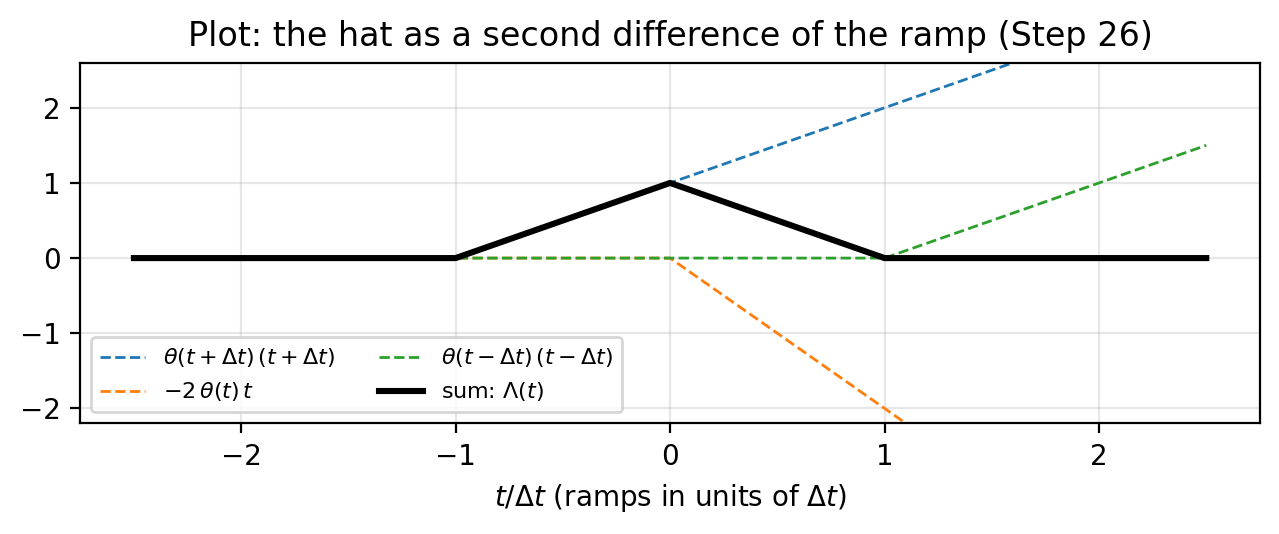

In [ ]:
_t = np.linspace(-2.5, 2.5, 1001)
_ramp = lambda v: np.where(v > 0, v, 0.0)
_fig, _ax = plt.subplots(figsize=(6.5, 2.8))
_ax.plot(_t, _ramp(_t + 1), "--", lw=1, label=r"$\theta(t+\Delta t)\,(t+\Delta t)$")
_ax.plot(_t, -2 * _ramp(_t), "--", lw=1, label=r"$-2\,\theta(t)\,t$")
_ax.plot(_t, _ramp(_t - 1), "--", lw=1, label=r"$\theta(t-\Delta t)\,(t-\Delta t)$")
_ax.plot(_t, f_hat(_t), "k", lw=2.2, label=r"sum: $\Lambda(t)$")
_ax.set_ylim(-2.2, 2.6)
_ax.set_xlabel(r"$t / \Delta t$ (ramps in units of $\Delta t$)")
_ax.set_title(r"Plot: the hat as a second difference of the ramp (Step 26)")
_ax.legend(loc="lower left", fontsize=8, ncol=2)
_ax.grid(alpha=0.3)
_fig.tight_layout()
_fig

In [ ]:
lam_ell = sp.IndexedBase("lambda", real=True)
eq28 = Eqn(lam(t), sp.Sum(mul(lam_ell[ell], Lam(t - tg[ell])), (ell, 0, M - 1)))
eq28b = Eqn(lam(t), mul(dt, sp.Sum(mul(lam_ell[ell], hh(t - tg[ell])), (ell, 0, M - 1))))
step(
    r"**Step 28.** Linear interpolation: one hat per bin. At $t = t_m$ only the term $\ell = m$ survives "
    r"(Step 27), so $\lambda(t_m) = \lambda_m$. With Step 19, and $\Delta t$ pulled out of the sum:",
    new(eq28),
    eq28b,
    order="none",
)

Step 28. Linear interpolation: one hat per bin. At \(t = t_m\) only the term \(\ell = m\) survives (Step 27), so \(\lambda(t_m) = \lambda_m\). With Step 19, and \(\Delta t\) pulled out of the sum: \[ \lambda{\left(t \right)} = \sum_{\ell=0}^{-1 + M} {\lambda}_{\ell} \Lambda{\left(t - {{t}}_{\ell} \right)} \] \[ \lambda{\left(t \right)} = \Delta t \sum_{\ell=0}^{-1 + M} {\lambda}_{\ell} \left(h * h\right){\left(t - {{t}}_{\ell} \right)} \]

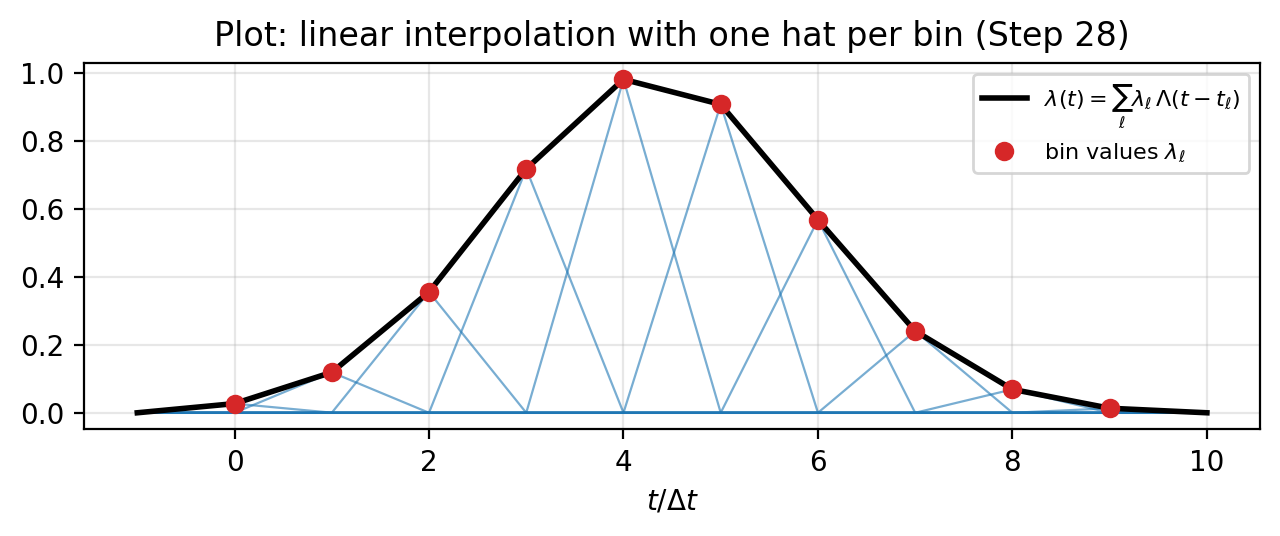

In [ ]:
_j = np.arange(10)
_lam = np.exp(-0.5 * ((_j - 4.3) / 1.6) ** 2)  # example bin values
_t = np.linspace(-1, 10, 1101)
_fig, _ax = plt.subplots(figsize=(6.5, 2.8))
for _jj, _l in zip(_j, _lam):
    _ax.plot(_t, _l * f_hat(_t - _jj), color="C0", lw=0.8, alpha=0.6)
_ax.plot(_t, sum(_l * f_hat(_t - _jj) for _jj, _l in zip(_j, _lam)), "k", lw=2, label=r"$\lambda(t) = \sum_\ell \lambda_\ell\,\Lambda(t - t_\ell)$")
_ax.plot(_j, _lam, "o", color="C3", label=r"bin values $\lambda_\ell$")
_ax.set_xlabel(r"$t / \Delta t$")
_ax.set_title(r"Plot: linear interpolation with one hat per bin (Step 28)")
_ax.legend(loc="upper right", fontsize=8)
_ax.grid(alpha=0.3)
_fig.tight_layout()
_fig

## 4. The discrete voltage

In [ ]:
hWl = sp.Function(r"\left(h * W * \lambda\right)")
eq29 = Eqn(V_k, mul(-q * N, hWl(t_k)))
step(
    r"**Step 29.** Insert Step 1 into Step 17; the constant $-qN$ comes out of the convolution.",
    eq29,
    order="none",
)

Step 29. Insert Step 1 into Step 17; the constant \(-qN\) comes out of the convolution. \[ V_{k} = - N q \left(h * W * \lambda\right){\left(t_{k} \right)} \]

In [ ]:
_hW = sp.Function(r"\left(h * W * \left(h * h\right)(\cdot - t_{\ell})\right)")
eq30 = Eqn(V_k, mul(-q * N, dt, sp.Sum(mul(lam_ell[ell], _hW(t_k)), (ell, 0, M - 1))))
step(
    r"**Step 30.** Insert the interpolated $\lambda$ (Step 28). Convolution is linear: "
    r"$\Delta t$, the finite sum and the $\lambda_\ell$ come out.",
    eq30,
    order="none",
)

Step 30. Insert the interpolated \(\lambda\) (Step 28). Convolution is linear: \(\Delta t\), the finite sum and the \(\lambda_\ell\) come out. \[ V_{k} = - N q \Delta t \sum_{\ell=0}^{-1 + M} {\lambda}_{\ell} \left(h * W * \left(h * h\right)(\cdot - t_{\ell})\right){\left(t_{k} \right)} \]

In [ ]:
hWhh = sp.Function(r"\left(h * W * h * h\right)")
eq31 = Eqn(V_k, mul(-q * N, dt, sp.Sum(mul(lam_ell[ell], hWhh(t_k - tg[ell])), (ell, 0, M - 1))))
step(
    r"**Step 31.** The shifted factor shifts the whole convolution (Step 12, $a = t_\ell$).",
    eq31,
    order="none",
)

Step 31. The shifted factor shifts the whole convolution (Step 12, \(a = t_\ell\)). \[ V_{k} = - N q \Delta t \sum_{\ell=0}^{-1 + M} {\lambda}_{\ell} \left(h * W * h * h\right){\left(t_{k} - {{t}}_{\ell} \right)} \]

In [ ]:
k = sp.Symbol("k", integer=True)
n = sp.Symbol("n", integer=True)
Wt = sp.Function(r"\tilde{W}")
hhhW = sp.Function(r"\left(h * h * h * W\right)")
eq32 = Eqn(
    V_k, mul(-q * N, dt, sp.Sum(mul(lam_ell[ell], Wt(mul(add(k, -ell), dt))), (ell, 0, M - 1)))
)
step(
    r"**Step 32.** Reorder the convolution (commutative) and name it the effective wake $\tilde W$. "
    r"With $t_k = k\,\Delta t$ and $t_\ell = \ell\,\Delta t$ (Step 18) the argument is a whole number of bins:",
    key(new(Eqn(Wt(t), hhhW(t)))),
    key(eq32),
    order="none",
)

Step 32. Reorder the convolution (commutative) and name it the effective wake \(\tilde W\). With \(t_k = k\,\Delta t\) and \(t_\ell = \ell\,\Delta t\) (Step 18) the argument is a whole number of bins: \[ \tilde{W}{\left(t \right)} = \left(h * h * h * W\right){\left(t \right)} \] \[ V_{k} = - N q \Delta t \sum_{\ell=0}^{-1 + M} {\lambda}_{\ell} \tilde{W}{\left(\left(k - \ell\right) \Delta t \right)} \]

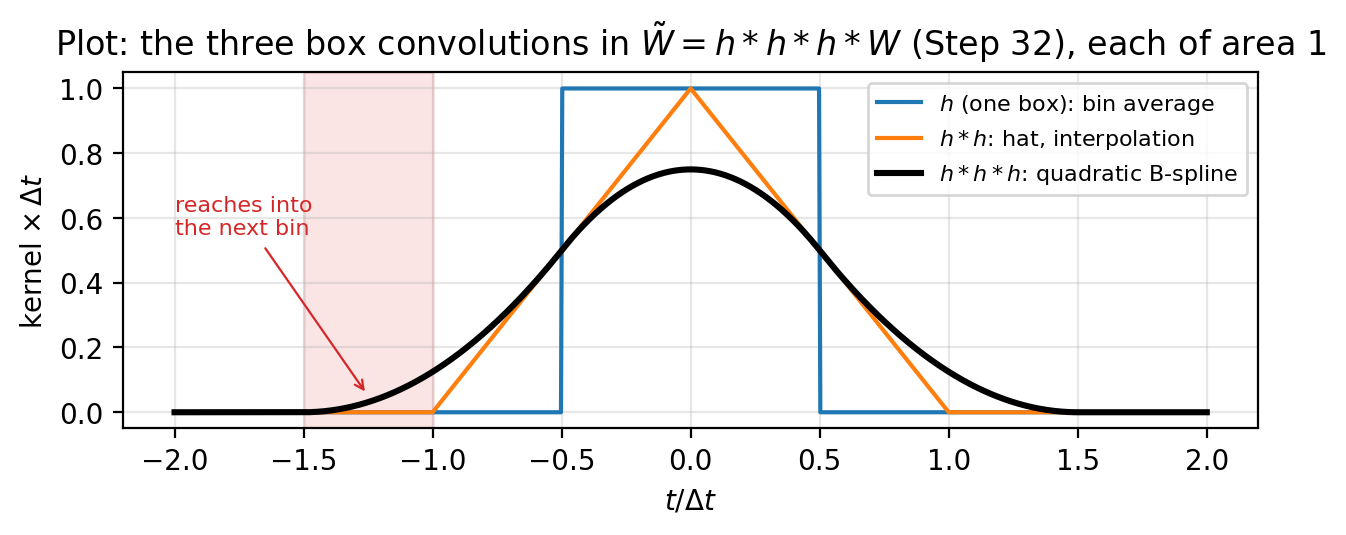

In [ ]:
_t = np.linspace(-2, 2, 1601)
_fig, _ax = plt.subplots(figsize=(6.5, 2.8))
_ax.plot(_t, f_h(_t), lw=1.5, label=r"$h$ (one box): bin average")
_ax.plot(_t, f_hat(_t), lw=1.5, label=r"$h * h$: hat, interpolation")
_ax.plot(_t, f_b2(_t), "k", lw=2.2, label=r"$h * h * h$: quadratic B-spline")
_ax.axvspan(-1.5, -1.0, color="C3", alpha=0.12)
_ax.annotate("reaches into\nthe next bin", xy=(-1.25, 0.05), xytext=(-2.0, 0.55), fontsize=8, color="C3",
             arrowprops={"arrowstyle": "->", "color": "C3", "lw": 0.8})
_ax.set_xlabel(r"$t / \Delta t$")
_ax.set_ylabel(r"kernel $\times\,\Delta t$")
_ax.set_title(r"Plot: the three box convolutions in $\tilde W = h * h * h * W$ (Step 32), each of area 1")
_ax.legend(loc="upper right", fontsize=8)
_ax.grid(alpha=0.3)
_fig.tight_layout()
_fig

## 5. The effective wake is a third difference

In [ ]:
dddW = sp.Function(r"\left(\delta\theta * \delta\theta * \delta\theta * W\right)")
eq33 = Eqn(Wt(t), mul(sp.Pow(dt, -3), dddW(t)))
step(
    r"**Step 33.** Insert $h = \frac{\delta\theta}{\Delta t}$ (Step 13) for all three kernels; "
    r"the constants come out.",
    eq33,
    order="none",
)

Step 33. Insert \(h = \frac{\delta\theta}{\Delta t}\) (Step 13) for all three kernels; the constants come out. \[ \tilde{W}{\left(t \right)} = \frac{\left(\delta\theta * \delta\theta * \delta\theta * W\right){\left(t \right)}}{\Delta t^{3}} \]

In [ ]:
W3 = sp.Function(r"\left(\theta * \theta * \theta * W\right)")
d3W3 = sp.Function(r"\delta^{3}\left(\theta * \theta * \theta * W\right)")
eq34 = Eqn(Wt(t), mul(sp.Pow(dt, -3), d3W3(t)))
step(
    r"**Step 34.** Move the three differences out (Step 6, three times). "
    r"$\theta * \theta * \theta * W$ is the wake integrated three times (Step 8).",
    key(eq34),
    order="none",
)

Step 34. Move the three differences out (Step 6, three times). \(\theta * \theta * \theta * W\) is the wake integrated three times (Step 8). \[ \tilde{W}{\left(t \right)} = \frac{\delta^{3}\left(\theta * \theta * \theta * W\right){\left(t \right)}}{\Delta t^{3}} \]

In [ ]:
_R = sp.Rational
d3f = sp.Function(r"\left(\delta^{3} f\right)")
eq35 = Eqn(
    d3f(t),
    add(
        f(t + _R(3, 2) * dt), mul(-3, f(t + dt / 2)), mul(3, f(t - dt / 2)), mul(-1, f(t - _R(3, 2) * dt))
    ),
)
step(
    r"**Step 35.** The third central difference, written out (binomial coefficients $1, -3, 3, -1$ "
    r"at the four points $t + \tfrac32\Delta t, \dots, t - \tfrac32\Delta t$)."
    "\n\n*Check: Step 3 applied three times minus this:*",
    eq35,
    diff0(delta(f(t), 3), eq35.rhs.doit()),
    order="none",
)

Step 35. The third central difference, written out (binomial coefficients \(1, -3, 3, -1\) at the four points \(t + \tfrac32\Delta t, \dots, t - \tfrac32\Delta t\)). 
 Check: Step 3 applied three times minus this: \[ \left(\delta^{3} f\right){\left(t \right)} = f{\left(t + \frac{3 \Delta t}{2} \right)} - 3 f{\left(t + \frac{\Delta t}{2} \right)} + 3 f{\left(t - \frac{\Delta t}{2} \right)} - f{\left(t - \frac{3 \Delta t}{2} \right)} \]\[ \text{difference} = 0 \]

## 6. The pole-residue wake

- $\alpha_p > 0$: decay rate, $\omega_p > 0$: oscillation frequency of mode $p$
- $r_p$: complex residue; each pole comes with its complex conjugate, so $W$ is real
- $\theta(t)$: causality, no wake before the source passes

In [ ]:
p = sp.Symbol("p", integer=True)
P = sp.Symbol("P", integer=True, positive=True)
r_p = sp.IndexedBase("r")
alpha = sp.IndexedBase("alpha", positive=True)
omega = sp.IndexedBase("omega", positive=True)
s_p = sp.IndexedBase("{s}")  # label "{s}" keeps it separate from any symbol s
eq36 = Eqn(s_p[p], -alpha[p] + sp.I * omega[p])
step(r"**Step 36.** Pole of mode $p$: decay rate as real part, frequency as imaginary part.", new(eq36))

Step 36. Pole of mode \(p\): decay rate as real part, frequency as imaginary part. \[ {{s}}_{p} = - {\alpha}_{p} + i {\omega}_{p} \]

In [ ]:
eq37 = Eqn(
    W(t),
    mul(
        theta(t),
        sp.Sum(
            add(
                mul(r_p[p], sp.exp(mul(s_p[p], t))),
                mul(sp.conjugate(r_p[p]), sp.exp(mul(sp.conjugate(s_p[p]), t))),
            ),
            (p, 1, P),
        ),
    ),
)
step(r"**Step 37.** Pole-residue wake: each mode with its complex-conjugate partner.", new(eq37), order="none")

Step 37. Pole-residue wake: each mode with its complex-conjugate partner. \[ W{\left(t \right)} = \theta\left(t\right) \sum_{p=1}^{P} \left({r}_{p} e^{{{s}}_{p} t} + \overline{{r}_{p}} e^{\overline{{{s}}_{p}} t}\right) \]

In [ ]:
g_p = sp.Function("g_p")
_w = sp.Symbol("w")
eq38 = Eqn(W(t), mul(2, sp.re(sp.Sum(mul(r_p[p], g_p(t)), (p, 1, P)))))
eq38b = Eqn(g_p(t), mul(theta(t), sp.exp(mul(s_p[p], t))))
step(
    r"**Step 38.** The partner term is the complex conjugate of the first ($\theta$ and $t$ are real), and "
    r"$w + \bar w = 2\,\mathrm{Re}\, w$; the real part of a sum is the sum of the real parts. "
    r"Name the causal exponential $g_p$:"
    "\n\n*Check of the identity:*",
    key(eq38),
    key(new(eq38b)),
    Eqn(
        sp.Add(_w, sp.conjugate(_w), -2 * sp.re(_w), evaluate=False),
        sp.expand_complex(_w + sp.conjugate(_w) - 2 * sp.re(_w)),
    ),
    order="none",
)

Step 38. The partner term is the complex conjugate of the first (\(\theta\) and \(t\) are real), and \(w + \bar w = 2\,\mathrm{Re}\, w\); the real part of a sum is the sum of the real parts. Name the causal exponential \(g_p\): 
 Check of the identity: \[ W{\left(t \right)} = 2 \operatorname{re}{\left(\sum_{p=1}^{P} {r}_{p} g_{p}{\left(t \right)}\right)} \] \[ g_{p}{\left(t \right)} = \theta\left(t\right) e^{{{s}}_{p} t} \] \[ w + \overline{w} - 2 \operatorname{re}{\left(w\right)} = 0 \]

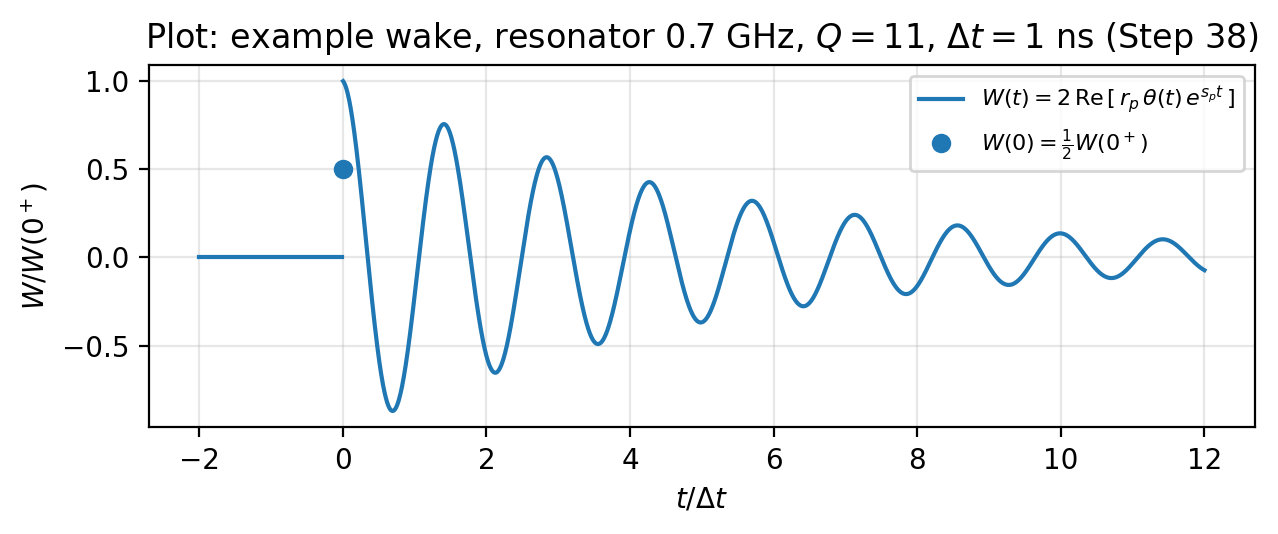

In [ ]:
_t = np.linspace(-2, 12, 2801)
_fig, _ax = plt.subplots(figsize=(6.5, 2.8))
_ax.plot(_t[_t < 0], f_W(_t[_t < 0]), "C0", lw=1.5)
_ax.plot(_t[_t > 0], f_W(_t[_t > 0]), "C0", lw=1.5, label=r"$W(t) = 2\,\mathrm{Re}\,[\,r_p\,\theta(t)\,e^{s_p t}\,]$")
_ax.plot([0], [0.5], "o", color="C0", label=r"$W(0) = \frac{1}{2} W(0^+)$")
_ax.set_xlabel(r"$t / \Delta t$")
_ax.set_ylabel(r"$W / W(0^+)$")
_ax.set_title(r"Plot: example wake, resonator 0.7 GHz, $Q = 11$, $\Delta t = 1$ ns (Step 38)")
_ax.legend(loc="upper right", fontsize=8)
_ax.grid(alpha=0.3)
_fig.tight_layout()
_fig

In [ ]:
_d3G = sp.Function(r"\delta^{3} G_{p}")
_G = sp.Function("G_p")
tttg = sp.Function(r"\left(\theta * \theta * \theta * g_{p}\right)")
eq39 = Eqn(Wt(t), mul(2, sp.re(sp.Sum(mul(r_p[p], sp.Pow(dt, -3), _d3G(t)), (p, 1, P)))))
step(
    r"**Step 39.** Put Step 38 into Step 34. Running integrals and differences are linear and real, "
    r"so they pass through the sum, the residues and $\mathrm{Re}$. One function per pole remains:",
    eq39,
    new(Eqn(_G(t), tttg(t))),
    order="none",
)

Step 39. Put Step 38 into Step 34. Running integrals and differences are linear and real, so they pass through the sum, the residues and \(\mathrm{Re}\). One function per pole remains: \[ \tilde{W}{\left(t \right)} = 2 \operatorname{re}{\left(\sum_{p=1}^{P} \frac{{r}_{p} \delta^{3} G_{p}{\left(t \right)}}{\Delta t^{3}}\right)} \] \[ G_{p}{\left(t \right)} = \left(\theta * \theta * \theta * g_{p}\right){\left(t \right)} \]

## 7. Three running integrals of one pole

$g_p$ is causal, so each $\theta\, *$ is an integral from $0$ to $t$ (Step 9).
*Each result is checked by differentiating: derivative minus integrand must be $0$, and so must the value at $t = 0$.*

In [ ]:
def runint_check(result, integrand):
    """Derivative of the result minus the integrand, and the result at t = 0."""
    return [
        Eqn(sp.Symbol(r"\text{difference}"), sp.simplify(sp.diff(result.doit(), t) - integrand.doit().subs(tp, t))),
        Eqn(sp.Symbol(r"\text{value at } t = 0"), sp.simplify(result.doit().subs(t, 0))),
    ]

In [ ]:
tg1 = sp.Function(r"\left(\theta * g_{p}\right)")
int40 = sp.exp(mul(s_p[p], tp))
eq40 = Eqn(tg1(t), mul(theta(t), sp.Integral(int40, (tp, 0, t))))
step(r"**Step 40.** First running integral of $g_p = \theta(t)\, e^{s_p t}$.", eq40, order="none")

Step 40. First running integral of \(g_p = \theta(t)\, e^{s_p t}\). \[ \left(\theta * g_{p}\right){\left(t \right)} = \theta\left(t\right) \int\limits_{0}^{t} e^{{{s}}_{p} t'}\, dt' \]

In [ ]:
_s = s_p[p]
res41 = mul(sp.Pow(_s, -1), add(sp.exp(mul(_s, t)), -1))
step(
    r"**Step 41.** Evaluate."
    "\n\n*Check:*",
    Eqn(tg1(t), mul(theta(t), res41)),
    *runint_check(res41, int40),
    order="none",
)

Step 41. Evaluate. 
 Check: \[ \left(\theta * g_{p}\right){\left(t \right)} = \theta\left(t\right) \frac{e^{{{s}}_{p} t} - 1}{{{s}}_{p}} \]\[ \text{difference} = 0 \]\[ \text{value at } t = 0 = 0 \]

In [ ]:
tg2 = sp.Function(r"\left(\theta * \theta * g_{p}\right)")
int42 = res41.subs(t, tp)
eq42 = Eqn(tg2(t), mul(theta(t), sp.Integral(int42, (tp, 0, t))))
step(r"**Step 42.** Second running integral: integrate the result of Step 41.", eq42, order="none")

Step 42. Second running integral: integrate the result of Step 41. \[ \left(\theta * \theta * g_{p}\right){\left(t \right)} = \theta\left(t\right) \int\limits_{0}^{t} \frac{-1 + e^{t' {{s}}_{p}}}{{{s}}_{p}}\, dt' \]

In [ ]:
_s = s_p[p]
res43 = mul(sp.Pow(_s, -2), add(sp.exp(mul(_s, t)), -1, -mul(_s, t)))
step(
    r"**Step 43.** Evaluate."
    "\n\n*Check:*",
    Eqn(tg2(t), mul(theta(t), res43)),
    *runint_check(res43, int42),
    order="none",
)

Step 43. Evaluate. 
 Check: \[ \left(\theta * \theta * g_{p}\right){\left(t \right)} = \theta\left(t\right) \frac{e^{{{s}}_{p} t} - 1 - {{s}}_{p} t}{{{s}}_{p}^{2}} \]\[ \text{difference} = 0 \]\[ \text{value at } t = 0 = 0 \]

In [ ]:
G_p = sp.Function("G_p")
int44 = res43.subs(t, tp)
eq44 = Eqn(G_p(t), mul(theta(t), sp.Integral(int44, (tp, 0, t))))
step(r"**Step 44.** Third running integral: integrate the result of Step 43. This is $G_p$ of Step 39.", eq44, order="none")

Step 44. Third running integral: integrate the result of Step 43. This is \(G_p\) of Step 39. \[ G_{p}{\left(t \right)} = \theta\left(t\right) \int\limits_{0}^{t} \frac{-1 - t' {{s}}_{p} + e^{t' {{s}}_{p}}}{{{s}}_{p}^{2}}\, dt' \]

In [ ]:
_s = s_p[p]
res45 = mul(sp.Pow(_s, -3), add(sp.exp(mul(_s, t)), -1, -mul(_s, t), -mul(sp.Rational(1, 2), _s**2, t**2)))
step(
    r"**Step 45.** Evaluate. Each integration adds one more Taylor term of $e^{s_p t}$."
    "\n\n*Check:*",
    Eqn(G_p(t), mul(theta(t), res45)),
    *runint_check(res45, int44),
    order="none",
)

Step 45. Evaluate. Each integration adds one more Taylor term of \(e^{s_p t}\). 
 Check: \[ G_{p}{\left(t \right)} = \theta\left(t\right) \frac{e^{{{s}}_{p} t} - 1 - {{s}}_{p} t - \frac{{{s}}_{p}^{2} t^{2}}{2}}{{{s}}_{p}^{3}} \]\[ \text{difference} = 0 \]\[ \text{value at } t = 0 = 0 \]

In [ ]:
x = sp.Symbol("x")
Ecal = sp.Function(r"\mathcal{E}")
E_def = sp.exp(x) - 1 - x - x**2 / 2
step(
    r"**Step 46.** Define $\mathcal{E}$: the exponential minus its Taylor polynomial up to second order, "
    r"i.e. the Taylor series of $e^x$ without its first three terms. "
    r"It is small near $0$, $\mathcal{E}(x) \approx \frac{x^3}{6}$ (evaluate it by its series there).",
    new(Eqn(Ecal(x), sp.Add(sp.exp(x), -1, -x, -x**2 / 2, evaluate=False))),
    Eqn(Ecal(x), sp.series(E_def, x, 0, 5)),
    order="none",
)

Step 46. Define \(\mathcal{E}\): the exponential minus its Taylor polynomial up to second order, i.e. the Taylor series of \(e^x\) without its first three terms. It is small near \(0\), \(\mathcal{E}(x) \approx \frac{x^3}{6}\) (evaluate it by its series there). \[ \mathcal{E}{\left(x \right)} = e^{x} - 1 - x - \frac{x^{2}}{2} \] \[ \mathcal{E}{\left(x \right)} = \frac{x^{3}}{6} + \frac{x^{4}}{24} + O\left(x^{5}\right) \]

In [ ]:
_s = s_p[p]
_Est = Eqn(
    Ecal(mul(_s, t)),
    add(sp.exp(mul(_s, t)), -1, -mul(_s, t), -mul(sp.Rational(1, 2), _s**2, t**2)),
)
_eq47 = Eqn(G_p(t), mul(sp.Pow(_s, -3), theta(t), Ecal(mul(_s, t))))
step(
    r"**Step 47.** Step 46 at $x = s_p t$ is exactly the bracket of Step 45. So:"
    "\n\n*Check: Step 46 at x = s_p t minus the bracket above, and this result minus Step 45:*",
    new(r"x = s_p t"),
    _Est,
    key(_eq47),
    Eqn(sp.Symbol(r"\text{difference}"), sp.simplify(E_def.subs(x, _s * t) - _Est.rhs.doit())),
    Eqn(
        sp.Symbol(r"\text{difference}"),
        sp.simplify(_eq47.rhs.doit().replace(Ecal, lambda v: E_def.subs(x, v)) - theta(t) * res45.doit()),
    ),
    order="none",
)

Step 47. Step 46 at \(x = s_p t\) is exactly the bracket of Step 45. So: 
 Check: Step 46 at x = s_p t minus the bracket above, and this result minus Step 45: \[ x = s_p t \] \[ \mathcal{E}{\left({{s}}_{p} t \right)} = e^{{{s}}_{p} t} - 1 - {{s}}_{p} t - \frac{{{s}}_{p}^{2} t^{2}}{2} \] \[ G_{p}{\left(t \right)} = \frac{\theta\left(t\right) \mathcal{E}{\left({{s}}_{p} t \right)}}{{{s}}_{p}^{3}} \] \[ \text{difference} = 0 \]\[ \text{difference} = 0 \]

## 8. On the grid: one formula for every bin distance

In [ ]:
I_p = sp.Function("I_p")
_d3G = sp.Function(r"\delta^{3} G_{p}")
Wn = sp.IndexedBase(r"\tilde{W}")
eq47 = Eqn(I_p(n), mul(sp.Pow(dt, -3), _d3G(mul(n, dt))))
step(
    r"**Step 48.** Step 39 at $t = n\,\Delta t$ (Step 32), with the per-pole part named $I_p(n)$:",
    new(Eqn(Wn[n], Wt(mul(n, dt)))),
    Eqn(Wn[n], mul(2, sp.re(sp.Sum(mul(r_p[p], I_p(n)), (p, 1, P))))),
    new(eq47),
    order="none",
)

Step 48. Step 39 at \(t = n\,\Delta t\) (Step 32), with the per-pole part named \(I_p(n)\): \[ {\tilde{W}}_{n} = \tilde{W}{\left(n \Delta t \right)} \] \[ {\tilde{W}}_{n} = 2 \operatorname{re}{\left(\sum_{p=1}^{P} {r}_{p} I_{p}{\left(n \right)}\right)} \] \[ I_{p}{\left(n \right)} = \frac{\delta^{3} G_{p}{\left(n \Delta t \right)}}{\Delta t^{3}} \]

In [ ]:
_R = sp.Rational
_G = lambda c: G_p(mul(add(n, c), dt))
eq48 = Eqn(
    I_p(n),
    mul(sp.Pow(dt, -3), add(_G(_R(3, 2)), mul(-3, _G(_R(1, 2))), mul(3, _G(-_R(1, 2))), mul(-1, _G(-_R(3, 2))))),
)
step(
    r"**Step 49.** Write out $\delta^3$ (Step 35) at $t = n\,\Delta t$: the four points are half-integer bins away.",
    eq48,
    order="none",
)

Step 49. Write out \(\delta^3\) (Step 35) at \(t = n\,\Delta t\): the four points are half-integer bins away. \[ I_{p}{\left(n \right)} = \frac{G_{p}{\left(\left(n + \frac{3}{2}\right) \Delta t \right)} - 3 G_{p}{\left(\left(n + \frac{1}{2}\right) \Delta t \right)} + 3 G_{p}{\left(\left(n - \frac{1}{2}\right) \Delta t \right)} - G_{p}{\left(\left(n - \frac{3}{2}\right) \Delta t \right)}}{\Delta t^{3}} \]

In [ ]:
sig = sp.IndexedBase(r"{\sigma}")
_s = s_p[p]
_G1 = Eqn(mul(sp.Pow(dt, -3), G_p(mul(a, dt))), mul(sp.Pow(dt, -3), sp.Pow(_s, -3), theta(mul(a, dt)), Ecal(mul(_s, a, dt))))
_G2 = Eqn(_G1.lhs, mul(sp.Pow(mul(_s, dt), -3), theta(a), Ecal(mul(mul(_s, dt), a))))
_G3 = Eqn(_G1.lhs, mul(sp.Pow(sig[p], -3), theta(a), Ecal(mul(sig[p], a))))
step(
    r"**Step 50.** Each point $t = a\,\Delta t$ in Step 47. Since $\Delta t > 0$, $\theta(a\,\Delta t) = \theta(a)$, "
    r"and $s_p$ and $\Delta t$ only appear together: the pole measured in bins, $\sigma_p = s_p\,\Delta t$ "
    r"(decay and phase per bin), shows up by itself.",
    new(r"t = a\,\Delta t"),
    _G1,
    _G2,
    new(Eqn(sig[p], mul(_s, dt))),
    _G3,
    order="none",
)

Step 50. Each point \(t = a\,\Delta t\) in Step 47. Since \(\Delta t > 0\), \(\theta(a\,\Delta t) = \theta(a)\), and \(s_p\) and \(\Delta t\) only appear together: the pole measured in bins, \(\sigma_p = s_p\,\Delta t\) (decay and phase per bin), shows up by itself. \[ t = a\,\Delta t \] \[ \frac{G_{p}{\left(a \Delta t \right)}}{\Delta t^{3}} = \frac{\theta\left(a \Delta t\right) \mathcal{E}{\left({{s}}_{p} a \Delta t \right)}}{\Delta t^{3} {{s}}_{p}^{3}} \]\[ \frac{G_{p}{\left(a \Delta t \right)}}{\Delta t^{3}} = \frac{1}{\Delta t^{3} {{s}}_{p}^{3}} \theta\left(a\right) \mathcal{E}{\left({{s}}_{p} \Delta t a \right)} \] \[ {{\sigma}}_{p} = {{s}}_{p} \Delta t \] \[ \frac{G_{p}{\left(a \Delta t \right)}}{\Delta t^{3}} = \frac{\theta\left(a\right) \mathcal{E}{\left({{\sigma}}_{p} a \right)}}{{{\sigma}}_{p}^{3}} \]

In [ ]:
_R = sp.Rational
nu = sp.Symbol("nu", integer=True)
_sg = sig[p]
a_nu = add(n, _R(3, 2), -nu)
c_nu = mul(sp.Pow(-1, nu), sp.binomial(3, nu))
_term = lambda c, v: mul(*([] if c == 1 else [c]), theta(add(n, v)), Ecal(mul(_sg, add(n, v))))
eq50 = Eqn(
    I_p(n),
    mul(sp.Pow(_sg, -3), add(_term(1, _R(3, 2)), _term(-3, _R(1, 2)), _term(3, -_R(1, 2)), _term(-1, -_R(3, 2)))),
)
eq50c = Eqn(I_p(n), mul(sp.Pow(_sg, -3), sp.Sum(mul(c_nu, theta(a_nu), Ecal(mul(_sg, a_nu))), (nu, 0, 3))))
# check: delta^3 of G_p(t) = theta(t) E(s t)/s^3 directly at t = n dt, numerically, for n = -3..3
_s, _dt = sp.Rational(-3, 10) + sp.Rational(21, 10) * sp.I, sp.Rational(7, 10)
_G = theta(t) * E_def.subs(x, sp.Symbol("s") * t) / sp.Symbol("s") ** 3
_direct = delta(_G, 3).subs({sp.Symbol("s"): _s, dt: _dt}) / _dt**3
_closed = eq50.rhs.doit().replace(Ecal, lambda v: E_def.subs(x, v)).subs(_sg, _s * _dt)
_err = max(abs(complex((_direct.subs(t, m * _dt) - _closed.subs(n, m)).evalf(30))) for m in range(-3, 4))
step(
    r"**Step 51.** Step 50 in all four terms of Step 49: one closed formula for every $n$. "
    r"Compactly, with the binomial weights $c_\nu = (-1)^\nu \binom{3}{\nu}$ and the points $a_\nu = n + \tfrac32 - \nu$:"
    "\n\n*Check: Step 3 applied three times to G_p, at t = nΔt with s_p = −0.3 + 2.1i, Δt = 0.7, "
    f"n = −3…3: max |difference| = {_err:.1e}*",
    eq50,
    new(r"c_\nu = (-1)^\nu \binom{3}{\nu}, \qquad a_\nu = n + \tfrac32 - \nu"),
    key(eq50c),
    order="none",
)

Step 51. Step 50 in all four terms of Step 49: one closed formula for every \(n\). Compactly, with the binomial weights \(c_\nu = (-1)^\nu \binom{3}{\nu}\) and the points \(a_\nu = n + \tfrac32 - \nu\): 
 Check: Step 3 applied three times to G_p, at t = nΔt with s_p = −0.3 + 2.1i, Δt = 0.7, n = −3…3: max |difference| = 5.3e-141 \[ I_{p}{\left(n \right)} = \frac{\theta\left(n + \frac{3}{2}\right) \mathcal{E}{\left({{\sigma}}_{p} \left(n + \frac{3}{2}\right) \right)} - 3 \theta\left(n + \frac{1}{2}\right) \mathcal{E}{\left({{\sigma}}_{p} \left(n + \frac{1}{2}\right) \right)} + 3 \theta\left(n - \frac{1}{2}\right) \mathcal{E}{\left({{\sigma}}_{p} \left(n - \frac{1}{2}\right) \right)} - \theta\left(n - \frac{3}{2}\right) \mathcal{E}{\left({{\sigma}}_{p} \left(n - \frac{3}{2}\right) \right)}}{{{\sigma}}_{p}^{3}} \] \[ c_\nu = (-1)^\nu \binom{3}{\nu}, \qquad a_\nu = n + \tfrac32 - \nu \] \[ I_{p}{\left(n \right)} = \frac{\sum_{\nu=0}^{3} \left(-1\right)^{\nu} {\binom{3}{\nu}} \theta\left(n + \frac{3}{2} - \nu\right) \mathcal{E}{\left({{\sigma}}_{p} \left(n + \frac{3}{2} - \nu\right) \right)}}{{{\sigma}}_{p}^{3}} \]

In [ ]:
step(
    r"**Step 52. Case $n \le -2$ (bins ahead of the source).** All four points $a_\nu \le -\tfrac12 < 0$: "
    r"every $\theta$ is $0$. Causality, smeared over one bin at most by the boxes."
    "\n\n*Check: Step 51 at n = −2, −3:*",
    Eqn(I_p(n), 0),
    Eqn(I_p(-2), eq50.rhs.doit().subs(n, -2)),
    Eqn(I_p(-3), eq50.rhs.doit().subs(n, -3)),
)

Step 52. Case \(n \le -2\) (bins ahead of the source). All four points \(a_\nu \le -\tfrac12 < 0\): every \(\theta\) is \(0\). Causality, smeared over one bin at most by the boxes. 
 Check: Step 51 at n = −2, −3: \[ I_{p}{\left(n \right)} = 0 \]\[ I_{p}{\left(-2 \right)} = 0 \]\[ I_{p}{\left(-3 \right)} = 0 \]

### Far field: $n \ge 2$

In [ ]:
eq52 = Eqn(I_p(n), mul(sp.Pow(sig[p], -3), sp.Sum(mul(c_nu, Ecal(mul(sig[p], a_nu))), (nu, 0, 3))))
step(
    r"**Step 53. Case $n \ge 2$.** All four points $a_\nu \ge \tfrac12 > 0$: every $\theta$ is $1$ (the boxes never "
    r"see the jump of the wake at $t = 0$).",
    eq52,
    order="none",
)

Step 53. Case \(n \ge 2\). All four points \(a_\nu \ge \tfrac12 > 0\): every \(\theta\) is \(1\) (the boxes never see the jump of the wake at \(t = 0\)). \[ I_{p}{\left(n \right)} = \frac{\sum_{\nu=0}^{3} \left(-1\right)^{\nu} {\binom{3}{\nu}} \mathcal{E}{\left({{\sigma}}_{p} \left(n + \frac{3}{2} - \nu\right) \right)}}{{{\sigma}}_{p}^{3}} \]

In [ ]:
_sum = lambda e: sp.Sum(sp.Mul(c_nu, e, evaluate=False), (nu, 0, 3))
_sg = sig[p]
step(
    r"**Step 54.** Insert $\mathcal{E}(x) = e^x - 1 - x - \tfrac{x^2}{2}$: the polynomial parts carry the "
    r"weights $c_\nu$ times $1$, $a_\nu$, $a_\nu^2$, and a third difference of a polynomial of degree $\le 2$ "
    r"vanishes, **for every $n$**:",
    Eqn(_sum(1), _sum(1).doit()),
    Eqn(_sum(a_nu), sp.expand(_sum(a_nu).doit())),
    Eqn(_sum(a_nu**2), sp.expand(_sum(a_nu**2).doit())),
    order="none",
)

Step 54. Insert \(\mathcal{E}(x) = e^x - 1 - x - \tfrac{x^2}{2}\): the polynomial parts carry the weights \(c_\nu\) times \(1\), \(a_\nu\), \(a_\nu^2\), and a third difference of a polynomial of degree \(\le 2\) vanishes, for every \(n\) : \[ \sum_{\nu=0}^{3} \left(-1\right)^{\nu} {\binom{3}{\nu}} 1 = 0 \]\[ \sum_{\nu=0}^{3} \left(-1\right)^{\nu} {\binom{3}{\nu}} \left(n + \frac{3}{2} - \nu\right) = 0 \]\[ \sum_{\nu=0}^{3} \left(-1\right)^{\nu} {\binom{3}{\nu}} \left(n + \frac{3}{2} - \nu\right)^{2} = 0 \]

In [ ]:
_R = sp.Rational
_sg = sig[p]
_e = lambda c, v: sp.exp(mul(_sg, add(n, v))) if c == 1 else mul(c, sp.exp(mul(_sg, add(n, v))))
eq54 = Eqn(I_p(n), mul(sp.Pow(_sg, -3), sp.Sum(mul(c_nu, sp.exp(mul(_sg, a_nu))), (nu, 0, 3))))
eq54b = Eqn(
    I_p(n), mul(sp.Pow(_sg, -3), add(_e(1, _R(3, 2)), _e(-3, _R(1, 2)), _e(3, -_R(1, 2)), _e(-1, -_R(3, 2))))
)
step(
    r"**Step 55.** Only the exponentials remain. Written out:"
    "\n\n*Check: sum written out minus the written-out terms:*",
    eq54,
    eq54b,
    Eqn(sp.Symbol(r"\text{difference}"), sp.simplify(eq54.rhs.doit() - eq54b.rhs.doit())),
    order="none",
)

Step 55. Only the exponentials remain. Written out: 
 Check: sum written out minus the written-out terms: \[ I_{p}{\left(n \right)} = \frac{\sum_{\nu=0}^{3} \left(-1\right)^{\nu} {\binom{3}{\nu}} e^{{{\sigma}}_{p} \left(n + \frac{3}{2} - \nu\right)}}{{{\sigma}}_{p}^{3}} \]\[ I_{p}{\left(n \right)} = \frac{e^{{{\sigma}}_{p} \left(n + \frac{3}{2}\right)} - 3 e^{{{\sigma}}_{p} \left(n + \frac{1}{2}\right)} + 3 e^{{{\sigma}}_{p} \left(n - \frac{1}{2}\right)} - e^{{{\sigma}}_{p} \left(n - \frac{3}{2}\right)}}{{{\sigma}}_{p}^{3}} \]\[ \text{difference} = 0 \]

In [ ]:
_R = sp.Rational
_sg = sig[p]
_e = lambda c, v: sp.exp(mul(_sg, v)) if c == 1 else mul(c, sp.exp(mul(_sg, v)))
eq55 = Eqn(
    I_p(n),
    mul(sp.exp(mul(_sg, n)), sp.Pow(_sg, -3), add(_e(1, _R(3, 2)), _e(-3, _R(1, 2)), _e(3, -_R(1, 2)), _e(-1, -_R(3, 2)))),
)
step(
    r"**Step 56.** Split $e^{\sigma_p (n + c)} = e^{\sigma_p n}\, e^{\sigma_p c}$ and pull $e^{\sigma_p n}$ out."
    "\n\n*Check: this step minus the previous one:*",
    eq55,
    Eqn(sp.Symbol(r"\text{difference}"), sp.simplify(sp.expand(eq55.rhs.doit() - eq54b.rhs.doit()))),
    order="none",
)

Step 56. Split \(e^{\sigma_p (n + c)} = e^{\sigma_p n}\, e^{\sigma_p c}\) and pull \(e^{\sigma_p n}\) out. 
 Check: this step minus the previous one: \[ I_{p}{\left(n \right)} = \frac{e^{{{\sigma}}_{p} n} \left(e^{{{\sigma}}_{p} \frac{3}{2}} - 3 e^{{{\sigma}}_{p} \frac{1}{2}} + 3 e^{{{\sigma}}_{p} \left(- \frac{1}{2}\right)} - e^{{{\sigma}}_{p} \left(- \frac{3}{2}\right)}\right)}{{{\sigma}}_{p}^{3}} \]\[ \text{difference} = 0 \]

In [ ]:
_sg = sig[p]
Far = sp.Function(r"I^{\mathrm{far}}_p")
H1 = mul(2, sp.sinh(mul(sp.Rational(1, 2), _sg)), sp.Pow(_sg, -1))
eq56 = Eqn(Far(n), mul(sp.exp(mul(_sg, n)), sp.Pow(H1, 3, evaluate=False)))
_cube = sp.Pow(add(sp.exp(_sg / 2), -sp.exp(-_sg / 2)), 3)
# one box alone: integral of h(t) e^{-s t} over all t, in terms of sigma = s dt
_s = sp.Symbol("s")
_box = sp.Integral(h_def.rewrite(sp.Piecewise) * sp.exp(-_s * t), (t, -sp.oo, sp.oo))
_boxval = sp.integrate(_box.function, (t, -sp.oo, sp.oo), conds="none")
step(
    r"**Step 57.** The bracket is a cube, $(a - b)^3 = a^3 - 3a^2 b + 3ab^2 - b^3$ with $a = e^{\sigma_p/2}$, "
    r"$b = e^{-\sigma_p/2}$, and $a - b = 2\sinh\frac{\sigma_p}{2}$. Exponentials are eigenfunctions of "
    r"convolution: each of the three boxes just multiplies by its own factor "
    r"$\int h(t)\, e^{-s_p t}\, dt = \frac{2\sinh(\sigma_p/2)}{\sigma_p}$. "
    r"**Far field: a geometric sequence in $n$, factor $e^{\sigma_p}$ per bin.**"
    "\n\n*Check: cube minus Step 56, and the single-box integral minus the factor:*",
    key(new(eq56)),
    Eqn(sp.Symbol(r"\text{difference}"), sp.simplify(sp.expand(sp.exp(_sg * n) * _cube / _sg**3 - eq55.rhs.doit()))),
    Eqn(
        sp.Symbol(r"\text{difference}"),
        sp.simplify((_boxval - H1.doit().subs(_sg, _s * dt)).rewrite(sp.exp)),
    ),
    order="none",
)

Step 57. The bracket is a cube, \((a - b)^3 = a^3 - 3a^2 b + 3ab^2 - b^3\) with \(a = e^{\sigma_p/2}\), \(b = e^{-\sigma_p/2}\), and \(a - b = 2\sinh\frac{\sigma_p}{2}\). Exponentials are eigenfunctions of convolution: each of the three boxes just multiplies by its own factor \(\int h(t)\, e^{-s_p t}\, dt = \frac{2\sinh(\sigma_p/2)}{\sigma_p}\). Far field: a geometric sequence in \(n\), factor \(e^{\sigma_p}\) per bin. 
 Check: cube minus Step 56, and the single-box integral minus the factor: \[ I^{\mathrm{far}}_p{\left(n \right)} = e^{{{\sigma}}_{p} n} \left(\frac{2 \sinh{\left(\frac{{{\sigma}}_{p}}{2} \right)}}{{{\sigma}}_{p}}\right)^{3} \] \[ \text{difference} = 0 \]\[ \text{difference} = 0 \]

### Near field: what causality cuts off

In [ ]:
Near = sp.Function(r"I^{\mathrm{near}}_p")
_sg = sig[p]
eq57 = Eqn(Near(n), add(I_p(n), mul(-1, Far(n))))
eq57b = Eqn(
    Near(n), mul(sp.Pow(_sg, -3), sp.Sum(mul(c_nu, add(theta(a_nu), -1), Ecal(mul(_sg, a_nu))), (nu, 0, 3)))
)
step(
    r"**Step 58.** Take the far-field formula as a function of **every** $n$ and call the rest the near field. "
    r"Steps 54–57 hold for every $n$, so $I^{\mathrm{far}}_p(n) = \sigma_p^{-3}\sum_\nu c_\nu\, \mathcal{E}(\sigma_p a_\nu)$; "
    r"subtract it from Step 51. $\theta(a_\nu) - 1$ is $-1$ for $a_\nu < 0$ and $0$ for $a_\nu > 0$: only the points behind "
    r"the jump remain, each with the Taylor polynomial removed.",
    new(eq57),
    eq57b,
    order="none",
)

Step 58. Take the far-field formula as a function of every \(n\) and call the rest the near field. Steps 54–57 hold for every \(n\), so \(I^{\mathrm{far}}_p(n) = \sigma_p^{-3}\sum_\nu c_\nu\, \mathcal{E}(\sigma_p a_\nu)\); subtract it from Step 51. \(\theta(a_\nu) - 1\) is \(-1\) for \(a_\nu < 0\) and \(0\) for \(a_\nu > 0\): only the points behind the jump remain, each with the Taylor polynomial removed. \[ I^{\mathrm{near}}_p{\left(n \right)} = I_{p}{\left(n \right)} - I^{\mathrm{far}}_p{\left(n \right)} \] \[ I^{\mathrm{near}}_p{\left(n \right)} = \frac{\sum_{\nu=0}^{3} \left(-1\right)^{\nu} {\binom{3}{\nu}} \left(\theta\left(n + \frac{3}{2} - \nu\right) - 1\right) \mathcal{E}{\left({{\sigma}}_{p} \left(n + \frac{3}{2} - \nu\right) \right)}}{{{\sigma}}_{p}^{3}} \]

In [ ]:
_R = sp.Rational
_sg = sig[p]
_E = lambda c, v: Ecal(mul(v, _sg)) if c == 1 else mul(c, Ecal(mul(v, _sg)))
_forms = {
    -1: add(_E(3, -_R(1, 2)), _E(-3, -_R(3, 2)), _E(1, -_R(5, 2))),
    0: add(_E(-3, -_R(1, 2)), _E(1, -_R(3, 2))),
    1: _E(1, -_R(1, 2)),
    2: sp.Integer(0),
}
_ev = lambda e: e.doit().replace(Ecal, lambda v: E_def.subs(x, v))
_diffs = [
    sp.simplify(sp.expand(_ev(f / _sg**3) - (_ev(eq50.rhs) - eq56.rhs.doit()).subs(n, m)).rewrite(sp.exp))
    for m, f in _forms.items()
]
step(
    r"**Step 59.** Step 58 for each $n$ (points $a_\nu = n + \tfrac32, n + \tfrac12, n - \tfrac12, n - \tfrac32$ "
    r"with weights $1, -3, 3, -1$; keep those with $a_\nu < 0$ and flip their sign). "
    r"Non-trivial on three bins only: for $n \ge 2$ nothing is cut ($I^{\mathrm{near}}_p = 0$), for $n \le -2$ it "
    r"cancels the far field, $I^{\mathrm{near}}_p = -I^{\mathrm{far}}_p$, since $I_p = 0$ there (Step 52)."
    "\n\n*Check: (Step 51) − (Step 57) − (this), for n = −1, 0, 1, 2:* "
    + ", ".join(f"**{d}**" for d in _diffs),
    *[Eqn(Near(m), mul(f, sp.Pow(_sg, -3)) if f != 0 else f) for m, f in _forms.items()],
    order="none",
)

Step 59. Step 58 for each \(n\) (points \(a_\nu = n + \tfrac32, n + \tfrac12, n - \tfrac12, n - \tfrac32\) with weights \(1, -3, 3, -1\); keep those with \(a_\nu < 0\) and flip their sign). Non-trivial on three bins only: for \(n \ge 2\) nothing is cut (\(I^{\mathrm{near}}_p = 0\)), for \(n \le -2\) it cancels the far field, \(I^{\mathrm{near}}_p = -I^{\mathrm{far}}_p\), since \(I_p = 0\) there (Step 52). 
 Check: (Step 51) − (Step 57) − (this), for n = −1, 0, 1, 2: 0 , 0 , 0 , 0 \[ I^{\mathrm{near}}_p{\left(-1 \right)} = \frac{3 \mathcal{E}{\left(- \frac{{{\sigma}}_{p}}{2} \right)} - 3 \mathcal{E}{\left(- \frac{3 {{\sigma}}_{p}}{2} \right)} + \mathcal{E}{\left(- \frac{5 {{\sigma}}_{p}}{2} \right)}}{{{\sigma}}_{p}^{3}} \]\[ I^{\mathrm{near}}_p{\left(0 \right)} = \frac{- 3 \mathcal{E}{\left(- \frac{{{\sigma}}_{p}}{2} \right)} + \mathcal{E}{\left(- \frac{3 {{\sigma}}_{p}}{2} \right)}}{{{\sigma}}_{p}^{3}} \]\[ I^{\mathrm{near}}_p{\left(1 \right)} = \frac{\mathcal{E}{\left(- \frac{{{\sigma}}_{p}}{2} \right)}}{{{\sigma}}_{p}^{3}} \]\[ I^{\mathrm{near}}_p{\left(2 \right)} = 0 \]

In [ ]:
step(
    r"**Step 60. Result.** The bin voltage is a discrete convolution with the effective wake; per pole, a "
    r"geometric far field plus a near-field correction on the three bins around the source.",
    Eqn(V_k, mul(-q * N, dt, sp.Sum(mul(lam_ell[ell], Wn[add(k, -ell)]), (ell, 0, add(M, -1))))),
    Eqn(Wn[n], mul(2, sp.re(sp.Sum(mul(r_p[p], I_p(n)), (p, 1, P))))),
    Eqn(I_p(n), add(Far(n), Near(n))),
    order="none",
)

Step 60. Result. The bin voltage is a discrete convolution with the effective wake; per pole, a geometric far field plus a near-field correction on the three bins around the source. \[ V_{k} = - N q \Delta t \sum_{\ell=0}^{M - 1} {\lambda}_{\ell} {\tilde{W}}_{k - \ell} \]\[ {\tilde{W}}_{n} = 2 \operatorname{re}{\left(\sum_{p=1}^{P} {r}_{p} I_{p}{\left(n \right)}\right)} \]\[ I_{p}{\left(n \right)} = I^{\mathrm{far}}_p{\left(n \right)} + I^{\mathrm{near}}_p{\left(n \right)} \]

In [ ]:
import mpmath

# independent check: the quadratic B-spline beta = h * h * h written out piecewise, integrated numerically
_y = sp.Symbol("y", real=True)
_R = sp.Rational
_beta = sp.Piecewise(
    (_R(3, 4) - x**2, sp.Abs(x) <= _R(1, 2)), (_R(1, 2) * (_R(3, 2) - sp.Abs(x)) ** 2, sp.Abs(x) <= _R(3, 2)), (0, True)
)
_bnum = sp.lambdify(x, _beta, "mpmath")
_sv = complex(sp.Rational(-3, 10) + sp.Rational(21, 10) * sp.I)
_closed = eq50.rhs.doit().replace(Ecal, lambda v: E_def.subs(x, v))
_rows = []
for _n in range(-2, 5):
    _num = mpmath.quad(lambda yy: _bnum(_n - yy) * mpmath.exp(_sv * yy), [0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6])
    _err = abs(complex(_closed.subs({n: _n, sig[p]: _sv}).evalf(30)) - complex(_num))
    _s0 = sp.Symbol("s0")  # sp.limit needs a plain symbol
    _lim = sp.limit(_closed.subs(n, _n).subs(sig[p], _s0), _s0, 0)
    _lim_direct = sp.integrate(_beta.subs(x, _n - _y), (_y, 0, 6))
    _rows.append(f"| {_n} | {_err:.1e} | ${sp.latex(_lim)}$ | ${sp.latex(_lim_direct)}$ |")
mo.md(
    r"**Independent check** by a different route: $I_p(n) = \int_0^\infty \beta(n - y)\, e^{\sigma_p y}\, dy$ "
    r"with the quadratic B-spline $\beta$ worked out piece by piece. Numerical integral at $\sigma_p = -0.3 + 2.1i$, "
    r"and the limit $\sigma_p \to 0$ against $\int_0^\infty \beta(n - y)\, dy$:"
    "\n\n| n | abs(Step 51 − numerical) | limit σ→0 of Step 51 | direct |\n|---|---|---|---|\n" + "\n".join(_rows)
)

**Independent check** by a different route: $I_p(n) = \int_0^\infty \beta(n - y)\, e^{\sigma_p y}\, dy$ with the quadratic B-spline $\beta$ worked out piece by piece. Numerical integral at $\sigma_p = -0.3 + 2.1i$, and the limit $\sigma_p \to 0$ against $\int_0^\infty \beta(n - y)\, dy$:

| n | abs(Step 51 − numerical) | limit σ→0 of Step 51 | direct |
|---|---|---|---|
| -2 | 0.0e+00 | $0$ | $0$ |
| -1 | 2.6e-18 | $\frac{1}{48}$ | $\frac{1}{48}$ |
| 0 | 0.0e+00 | $\frac{1}{2}$ | $\frac{1}{2}$ |
| 1 | 1.4e-16 | $\frac{47}{48}$ | $\frac{47}{48}$ |
| 2 | 2.2e-16 | $1$ | $1$ |
| 3 | 4.2e-17 | $1$ | $1$ |
| 4 | 8.8e-17 | $1$ | $1$ |

## 9. Near-field taps and the far-field recursion

The split of Step 60 (far-field formula for every $n$, plus a correction) is exact, but not the
best one for computing: it would put the lags $n = -1, 0, 1$ into the recursion as well, which then
needs the charge of the *next* bin and factors $e^{-\sigma_p}$ that grow for strongly damped poles.
Better (as in the BLonD near-/far-field note): the recursion only takes lags $n \ge 2$, where the
far-field formula is exact anyway (Step 53); the three lags $n = -1, 0, 1$ are applied as three exact
taps; $n \le -2$ is zero (Step 52). Below, $\lambda_\ell = 0$ for bins outside $0, \dots, M - 1$.

In [ ]:
V_far = sp.Symbol(r"V_k^{\mathrm{far}}")
V_near = sp.Symbol(r"V_k^{\mathrm{near}}")
_pre = -q * N * dt
eq61 = Eqn(V_k, add(V_far, V_near))
eq61_far = Eqn(V_far, mul(_pre, sp.Sum(mul(lam_ell[ell], Wn[add(k, -ell)]), (ell, 0, add(k, -2)))))
eq61_near = Eqn(
    V_near,
    mul(_pre, add(mul(lam_ell[add(k, -1)], Wn[1]), mul(lam_ell[k], Wn[0]), mul(lam_ell[add(k, 1)], Wn[-1]))),
)
# check: for M = 6 bins and every k, full sum (with W_n = 0 for n <= -2, Step 52) minus the split
_M = 6
_lam = lambda jj: lam_ell[jj] if 0 <= jj < _M else 0
_W = lambda nn: Wn[nn] if nn >= -1 else 0
_diffs = []
for _k in range(_M):
    _full = sum(_lam(jj) * _W(_k - jj) for jj in range(_M))
    _split = sum(_lam(jj) * _W(_k - jj) for jj in range(0, _k - 1)) + sum(
        _lam(_k - mm) * _W(mm) for mm in (1, 0, -1)
    )
    _diffs.append(sp.expand(_full - _split))
step(
    r"**Step 61.** Split the sum of Step 60 by the lag $n = k - \ell$: $n \ge 2$ (bins $\ell \le k - 2$, far field), "
    r"$n = 1, 0, -1$ (the previous bin, the bin itself, the next bin: near field). The bins $\ell \ge k + 2$ "
    r"have $n \le -2$ and drop out (Step 52)."
    "\n\n*Check with M = 6 bins, for k = 0, …, 5 (full sum minus split):* "
    + ", ".join(f"**{d}**" for d in _diffs),
    new(eq61),
    eq61_far,
    eq61_near,
    order="none",
)

Step 61. Split the sum of Step 60 by the lag \(n = k - \ell\): \(n \ge 2\) (bins \(\ell \le k - 2\), far field), \(n = 1, 0, -1\) (the previous bin, the bin itself, the next bin: near field). The bins \(\ell \ge k + 2\) have \(n \le -2\) and drop out (Step 52). 
 Check with M = 6 bins, for k = 0, …, 5 (full sum minus split): 0 , 0 , 0 , 0 , 0 , 0 \[ V_{k} = V_k^{\mathrm{far}} + V_k^{\mathrm{near}} \] \[ V_k^{\mathrm{far}} = - N \Delta t q \sum_{\ell=0}^{k - 2} {\lambda}_{\ell} {\tilde{W}}_{k - \ell} \]\[ V_k^{\mathrm{near}} = - N \Delta t q \left({\lambda}_{k - 1} {\tilde{W}}_{1} + {\lambda}_{k} {\tilde{W}}_{0} + {\lambda}_{k + 1} {\tilde{W}}_{-1}\right) \]

In [ ]:
_R = sp.Rational
_sg = sig[p]
_E = lambda c, v: Ecal(mul(v, _sg)) if c == 1 else mul(c, Ecal(mul(v, _sg)))
_taps = {
    -1: _E(1, _R(1, 2)),
    0: add(_E(1, _R(3, 2)), _E(-3, _R(1, 2))),
    1: add(_E(1, _R(5, 2)), _E(-3, _R(3, 2)), _E(3, _R(1, 2))),
}
_ev = lambda e: e.doit().replace(Ecal, lambda v: E_def.subs(x, v))
_diffs = [sp.simplify(_ev(f / _sg**3) - _ev(eq50.rhs).subs(n, m)) for m, f in _taps.items()]
step(
    r"**Step 62. The three near-field taps.** Step 51 at $n = -1, 0, 1$: the points $a_\nu$ are half-integers, "
    r"so each $\theta(a_\nu)$ is $1$ for $a_\nu > 0$ and $0$ for $a_\nu < 0$; only the points after the jump at $a = 0$ (those with $a_\nu > 0$) stay. "
    r"Each tap is $\tilde W_m = 2\,\mathrm{Re}\sum_p r_p\, I_p(m)$, computed once per setup "
    r"(for small $|\sigma_p|$ evaluate $\mathcal{E}$ by its series, Step 46)."
    "\n\n*Check: Step 51 at n = −1, 0, 1 minus these:* " + ", ".join(f"**{d}**" for d in _diffs),
    *[key(Eqn(I_p(m), mul(f, sp.Pow(_sg, -3)))) for m, f in _taps.items()],
    order="none",
)

Step 62. The three near-field taps. Step 51 at \(n = -1, 0, 1\): the points \(a_\nu\) are half-integers, so each \(\theta(a_\nu)\) is \(1\) for \(a_\nu > 0\) and \(0\) for \(a_\nu < 0\); only the points after the jump at \(a = 0\) (those with \(a_\nu > 0\)) stay. Each tap is \(\tilde W_m = 2\,\mathrm{Re}\sum_p r_p\, I_p(m)\), computed once per setup (for small \(|\sigma_p|\) evaluate \(\mathcal{E}\) by its series, Step 46). 
 Check: Step 51 at n = −1, 0, 1 minus these: 0 , 0 , 0 \[ I_{p}{\left(-1 \right)} = \frac{\mathcal{E}{\left(\frac{{{\sigma}}_{p}}{2} \right)}}{{{\sigma}}_{p}^{3}} \] \[ I_{p}{\left(0 \right)} = \frac{\mathcal{E}{\left(\frac{3 {{\sigma}}_{p}}{2} \right)} - 3 \mathcal{E}{\left(\frac{{{\sigma}}_{p}}{2} \right)}}{{{\sigma}}_{p}^{3}} \] \[ I_{p}{\left(1 \right)} = \frac{\mathcal{E}{\left(\frac{5 {{\sigma}}_{p}}{2} \right)} - 3 \mathcal{E}{\left(\frac{3 {{\sigma}}_{p}}{2} \right)} + 3 \mathcal{E}{\left(\frac{{{\sigma}}_{p}}{2} \right)}}{{{\sigma}}_{p}^{3}} \]

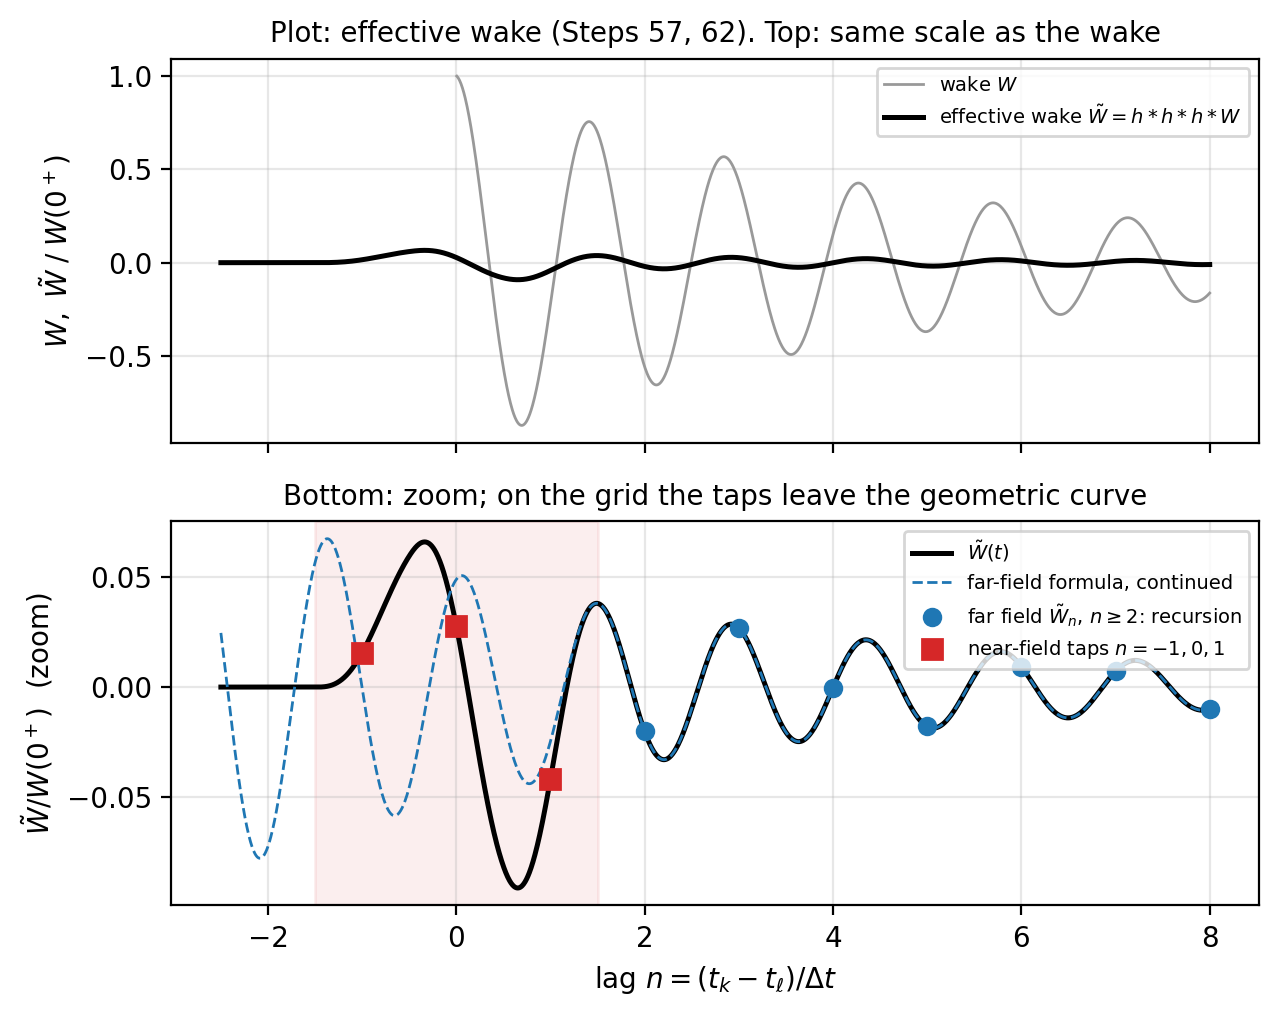

In [ ]:
_t = np.linspace(-2.5, 8, 2101)
_n = np.arange(-2, 9)
_far = _n >= 2
_near = (_n >= -1) & (_n <= 1)
_fig, (_a1, _a2) = plt.subplots(2, 1, figsize=(6.5, 5.2), sharex=True)
# top: wake and effective wake on the same scale -- the three boxes average the fast oscillation away
_a1.plot(_t[_t > 0], f_W(_t[_t > 0]), color="0.6", lw=1, label=r"wake $W$")
_a1.plot(_t, f_Wt(_t), "k", lw=1.8, label=r"effective wake $\tilde W = h*h*h*W$")
_a1.set_ylabel(r"$W,\ \tilde W \;/\; W(0^+)$")
_a1.set_title("Plot: effective wake (Steps 57, 62). Top: same scale as the wake", fontsize=10)
_a1.legend(loc="upper right", fontsize=7)
# bottom: zoom on the effective wake, with the grid values
_a2.plot(_t, f_Wt(_t), "k", lw=1.8, label=r"$\tilde W(t)$")
_a2.plot(_t, f_far(_t), "C0", ls="--", lw=1, label="far-field formula, continued")
_a2.plot(_n[_far], f_Wt(_n[_far]), "o", color="C0", label=r"far field $\tilde W_n$, $n \geq 2$: recursion")
_a2.plot(_n[_near], f_Wt(_n[_near]), "s", color="C3", ms=7, label=r"near-field taps $n = -1, 0, 1$")
_a2.axvspan(-1.5, 1.5, color="C3", alpha=0.08)
_a2.set_xlabel(r"lag $n = (t_k - t_\ell) / \Delta t$")
_a2.set_ylabel(r"$\tilde W / W(0^+)$  (zoom)")
_a2.set_title("Bottom: zoom; on the grid the taps leave the geometric curve", fontsize=10)
_a2.legend(loc="upper right", fontsize=7)
for _a in (_a1, _a2):
    _a.grid(alpha=0.3)
_fig.tight_layout()
_fig

In [ ]:
_sg = sig[p]
Fsig = mul(2, sp.sinh(mul(sp.Rational(1, 2), _sg)), sp.Pow(_sg, -1))
_far = mul(r_p[p], sp.exp(mul(_sg, add(k, -ell))), sp.Pow(Fsig, 3, evaluate=False))
eq63 = Eqn(
    V_far,
    mul(-q * N * dt, sp.Sum(mul(lam_ell[ell], 2, sp.re(sp.Sum(_far, (p, 1, P)))), (ell, 0, add(k, -2)))),
)
step(
    r"**Step 63. Far field.** Every lag in the far sum is $n = k - \ell \ge 2$, where the far-field formula "
    r"(Step 57) is exact. Insert it into Step 61:",
    eq63,
    order="none",
)

Step 63. Far field. Every lag in the far sum is \(n = k - \ell \ge 2\), where the far-field formula (Step 57) is exact. Insert it into Step 61: \[ V_k^{\mathrm{far}} = - N \Delta t q \sum_{\ell=0}^{k - 2} {\lambda}_{\ell} 2 \operatorname{re}{\left(\sum_{p=1}^{P} {r}_{p} e^{{{\sigma}}_{p} \left(k - \ell\right)} \left(\frac{2 \sinh{\left(\frac{{{\sigma}}_{p}}{2} \right)}}{{{\sigma}}_{p}}\right)^{3}\right)} \]

In [ ]:

_sg = sig[p]
eq64 = Eqn(
    V_far,
    mul(
        -q * N * dt,
        2,
        sp.re(
            sp.Sum(
                mul(
                    r_p[p],
                    sp.Pow(Fsig, 3, evaluate=False),
                    sp.Sum(mul(lam_ell[ell], sp.exp(mul(_sg, add(k, -ell)))), (ell, 0, add(k, -2))),
                ),
                (p, 1, P),
            )
        ),
    ),
)
# numerical check: real lambda_ell, 2 poles, k = 7
random.seed(1)
_lam = [random.uniform(0, 1) for _ in range(8)]
_poles = [(complex(0.3, -0.7), complex(-0.2, 4.39)), (complex(-1.1, 0.4), complex(-0.05, 1.3))]
_F = lambda s_: (2 * cmath.sinh(s_ / 2) / s_) ** 3
_k = 7
_a = sum(_lam[jj] * sum(2 * (r * cmath.exp(s_ * (_k - jj)) * _F(s_)).real for r, s_ in _poles) for jj in range(_k - 1))
_b = 2 * sum(r * _F(s_) * sum(_lam[jj] * cmath.exp(s_ * (_k - jj)) for jj in range(_k - 1)) for r, s_ in _poles).real
step(
    r"**Step 64.** The $\lambda_\ell$ are real and $\mathrm{Re}$ is linear: pull $2\,\mathrm{Re}$, the sum over the "
    r"poles and the $\ell$-independent factors out of the sum over $\ell$."
    "\n\n" + f"*Check with random real λ_ℓ, two poles, k = 7: |Step 63 − Step 64| = {abs(_a - _b):.1e}*",
    eq64,
    order="none",
)

Step 64. The \(\lambda_\ell\) are real and \(\mathrm{Re}\) is linear: pull \(2\,\mathrm{Re}\), the sum over the poles and the \(\ell\)-independent factors out of the sum over \(\ell\). 
 Check with random real λ_ℓ, two poles, k = 7: |Step 63 − Step 64| = 1.7e-16 \[ V_k^{\mathrm{far}} = - N \Delta t q 2 \operatorname{re}{\left(\sum_{p=1}^{P} {r}_{p} \left(\frac{2 \sinh{\left(\frac{{{\sigma}}_{p}}{2} \right)}}{{{\sigma}}_{p}}\right)^{3} \sum_{\ell=0}^{k - 2} {\lambda}_{\ell} e^{{{\sigma}}_{p} \left(k - \ell\right)}\right)} \]

In [ ]:
_sg = sig[p]
rho_p = sp.IndexedBase(r"\rho")
_rho_def = mul(r_p[p], sp.Pow(Fsig, 3, evaluate=False), sp.exp(mul(2, _sg)))
_rho_alt = mul(
    r_p[p], sp.Pow(mul(add(sp.exp(_sg), -1), sp.Pow(_sg, -1)), 3, evaluate=False), sp.exp(mul(sp.Rational(1, 2), _sg))
)
step(
    r"**Step 65.** Factor two bins out of each exponential, $e^{\sigma_p (k - \ell)} = e^{2\sigma_p}\, e^{\sigma_p (k - 2 - \ell)}$, "
    r"and collect the constants of pole $p$ into the readout residue $\rho_p$. "
    r"With $2\sinh\frac{\sigma_p}{2} = e^{-\sigma_p/2}\,(e^{\sigma_p} - 1)$ it takes a second form:"
    "\n\n*Check: first form minus second form:*",
    new(Eqn(rho_p[p], _rho_def)),
    key(Eqn(rho_p[p], _rho_alt)),
    Eqn(
        sp.Symbol(r"\text{difference}"),
        sp.simplify((_rho_def.doit() - _rho_alt.doit()).rewrite(sp.exp)),
    ),
    order="none",
)

Step 65. Factor two bins out of each exponential, \(e^{\sigma_p (k - \ell)} = e^{2\sigma_p}\, e^{\sigma_p (k - 2 - \ell)}\), and collect the constants of pole \(p\) into the readout residue \(\rho_p\). With \(2\sinh\frac{\sigma_p}{2} = e^{-\sigma_p/2}\,(e^{\sigma_p} - 1)\) it takes a second form: 
 Check: first form minus second form: \[ {\rho}_{p} = {r}_{p} \left(\frac{2 \sinh{\left(\frac{{{\sigma}}_{p}}{2} \right)}}{{{\sigma}}_{p}}\right)^{3} e^{2 {{\sigma}}_{p}} \] \[ {\rho}_{p} = {r}_{p} \left(\frac{e^{{{\sigma}}_{p}} - 1}{{{\sigma}}_{p}}\right)^{3} e^{\frac{{{\sigma}}_{p}}{2}} \] \[ \text{difference} = 0 \]

In [ ]:
S = sp.IndexedBase("S")
z = sp.IndexedBase("z")
eq66_z = Eqn(z[p], sp.exp(sig[p]))
eq66_S = Eqn(S[p, k], sp.Sum(mul(lam_ell[ell], sp.Pow(z[p], add(k, -2, -ell))), (ell, 0, add(k, -2))))
eq66 = Eqn(V_far, mul(-q * N * dt, 2, sp.re(sp.Sum(mul(rho_p[p], S[p, k]), (p, 1, P)))))
step(
    r"**Step 66.** Name the factor per bin $z_p$ and the remaining sum over $\ell$ the **state** $S_{p,k}$ of pole $p$ "
    r"at bin $k$: every charge $\lambda_\ell$, carried from bin $\ell$ to bin $k - 2$ (decayed and rotated by $z_p$ "
    r"per bin). The whole $k$-dependence of the far field sits in $S_{p,k}$.",
    new(eq66_z),
    new(eq66_S),
    eq66,
    order="none",
)

Step 66. Name the factor per bin \(z_p\) and the remaining sum over \(\ell\) the state \(S_{p,k}\) of pole \(p\) at bin \(k\): every charge \(\lambda_\ell\), carried from bin \(\ell\) to bin \(k - 2\) (decayed and rotated by \(z_p\) per bin). The whole \(k\)-dependence of the far field sits in \(S_{p,k}\). \[ {z}_{p} = e^{{{\sigma}}_{p}} \] \[ {S}_{p,k} = \sum_{\ell=0}^{k - 2} {\lambda}_{\ell} {z}_{p}^{k - 2 - \ell} \] \[ V_k^{\mathrm{far}} = - N \Delta t q 2 \operatorname{re}{\left(\sum_{p=1}^{P} {\rho}_{p} {S}_{p,k}\right)} \]

In [ ]:
eq67 = Eqn(
    S[p, k],
    add(lam_ell[add(k, -2)], sp.Sum(mul(lam_ell[ell], sp.Pow(z[p], add(k, -2, -ell))), (ell, 0, add(k, -3)))),
)
step(
    r"**Step 67.** Split off the newest term, $\ell = k - 2$ (exponent $0$, so $z_p^0 = 1$).",
    eq67,
    order="none",
)

Step 67. Split off the newest term, \(\ell = k - 2\) (exponent \(0\), so \(z_p^0 = 1\)). \[ {S}_{p,k} = {\lambda}_{k - 2} + \sum_{\ell=0}^{k - 3} {\lambda}_{\ell} {z}_{p}^{k - 2 - \ell} \]

In [ ]:
eq68 = Eqn(
    S[p, k],
    add(
        lam_ell[add(k, -2)],
        mul(z[p], sp.Sum(mul(lam_ell[ell], sp.Pow(z[p], add(add(k, -1), -2, -ell))), (ell, 0, add(add(k, -1), -2)))),
    ),
)
step(
    r"**Step 68.** Pull one factor $z_p$ out of the remaining sum: $z_p^{k-2-\ell} = z_p \cdot z_p^{(k-1)-2-\ell}$, "
    r"and write the upper limit $k - 3$ as $(k - 1) - 2$.",
    eq68,
    order="none",
)

Step 68. Pull one factor \(z_p\) out of the remaining sum: \(z_p^{k-2-\ell} = z_p \cdot z_p^{(k-1)-2-\ell}\), and write the upper limit \(k - 3\) as \((k - 1) - 2\). \[ {S}_{p,k} = {\lambda}_{k - 2} + {z}_{p} \sum_{\ell=0}^{\left(k - 1\right) - 2} {\lambda}_{\ell} {z}_{p}^{\left(k - 1\right) - 2 - \ell} \]

In [ ]:
eq69 = Eqn(S[p, k], add(mul(z[p], S[p, add(k, -1)]), lam_ell[add(k, -2)]))
# check: with the definition of Step 66 written out for k = 2..7, S_k - (z S_{k-1} + lambda_{k-2})
_Sdef = lambda kk: sum(lam_ell[jj] * z[p] ** (kk - 2 - jj) for jj in range(0, kk - 1))
_diffs = [sp.expand(_Sdef(kk) - (z[p] * _Sdef(kk - 1) + lam_ell[kk - 2])) for kk in range(2, 8)]
step(
    r"**Step 69. The far-field recursion.** The sum in Step 68 is the state of the previous bin, $S_{p,k-1}$ "
    r"(Step 66 with $k \to k - 1$). Per bin and pole: **decay** (multiply by $z_p$), **inject** the charge that "
    r"is now two bins old, $\lambda_{k-2}$. Start: $S_{p,k} = 0$ for $k < 2$ (no charge due yet). "
    r"Nothing is approximated: the recursion is the sum of Step 66, only bracketed differently."
    "\n\n*Check with Step 66 written out, for k = 2, …, 7:* " + ", ".join(f"**{d}**" for d in _diffs),
    key(eq69),
    order="none",
)

Step 69. The far-field recursion. The sum in Step 68 is the state of the previous bin, \(S_{p,k-1}\) (Step 66 with \(k \to k - 1\)). Per bin and pole: decay (multiply by \(z_p\)), inject the charge that is now two bins old, \(\lambda_{k-2}\). Start: \(S_{p,k} = 0\) for \(k < 2\) (no charge due yet). Nothing is approximated: the recursion is the sum of Step 66, only bracketed differently. 
 Check with Step 66 written out, for k = 2, …, 7: 0 , 0 , 0 , 0 , 0 , 0 \[ {S}_{p,k} = {z}_{p} {S}_{p,k - 1} + {\lambda}_{k - 2} \]

In [ ]:

# extreme damping: sigma = -400 + 3i (alpha dt = 400)
_s = complex(-400, 3)
_vals = {
    r"|z_p|": abs(cmath.exp(_s)),
    r"\left|\frac{e^{\sigma_p} - 1}{\sigma_p}\right|": abs((cmath.exp(_s) - 1) / _s),
    r"|e^{\sigma_p/2}|": abs(cmath.exp(_s / 2)),
}
step(
    r"**Step 70. Why the state lags two bins.** For a damped pole, $\mathrm{Re}\,\sigma_p \le 0$, every factor in the "
    r"recursion and its readout is bounded by one: $|z_p| = e^{\mathrm{Re}\,\sigma_p} \le 1$; "
    r"$\left|\frac{e^{\sigma_p} - 1}{\sigma_p}\right| = \left|\int_0^1 e^{\sigma_p u}\, du\right| \le 1$; "
    r"$|e^{\sigma_p/2}| \le 1$. So $|\rho_p| \le |r_p|$ (second form of Step 65), and nothing can overflow at any "
    r"bin width. A state referred to bin $k$ itself would need $e^{-2\sigma_p}$ in the readout instead, which "
    r"grows like $e^{2\alpha_p \Delta t}$."
    "\n\n*At σ_p = −400 + 3i (α_p Δt = 400):* "
    + ", ".join(f"${name} = {val:.2e}$" for name, val in _vals.items())
    + f", while $|e^{{-2\\sigma_p}}| = e^{{800}} \\approx 10^{{{800 / math.log(10):.0f}}}$, "
    "beyond the largest double ($\\approx 1.8 \\cdot 10^{308}$).",
)

Step 70. Why the state lags two bins. For a damped pole, \(\mathrm{Re}\,\sigma_p \le 0\), every factor in the recursion and its readout is bounded by one: \(|z_p| = e^{\mathrm{Re}\,\sigma_p} \le 1\); \(\left|\frac{e^{\sigma_p} - 1}{\sigma_p}\right| = \left|\int_0^1 e^{\sigma_p u}\, du\right| \le 1\); \(|e^{\sigma_p/2}| \le 1\). So \(|\rho_p| \le |r_p|\) (second form of Step 65), and nothing can overflow at any bin width. A state referred to bin \(k\) itself would need \(e^{-2\sigma_p}\) in the readout instead, which grows like \(e^{2\alpha_p \Delta t}\). 
 At σ_p = −400 + 3i (α_p Δt = 400): \(|z_p| = 1.92e-174\), \(\left|\frac{e^{\sigma_p} - 1}{\sigma_p}\right| = 2.50e-03\), \(|e^{\sigma_p/2}| = 1.38e-87\), while \(|e^{-2\sigma_p}| = e^{800} \approx 10^{347}\), beyond the largest double (\(\approx 1.8 \cdot 10^{308}\)).

In [ ]:

eq71_S = Eqn(S[p, k], add(mul(z[p], S[p, add(k, -1)]), lam_ell[add(k, -2)]))
eq71_V = Eqn(
    V_k,
    mul(
        -q * N * dt,
        add(
            mul(2, sp.re(sp.Sum(mul(rho_p[p], S[p, k]), (p, 1, P)))),
            mul(lam_ell[add(k, -1)], Wn[1]),
            mul(lam_ell[k], Wn[0]),
            mul(lam_ell[add(k, 1)], Wn[-1]),
        ),
    ),
)
# end-to-end check: direct discrete convolution with the exact kernel of Step 51 vs. recursion + taps
random.seed(7)
_M = 40
_lam = [random.uniform(0, 1) for _ in range(_M)]
_poles = [(complex(1.9992e8, 9.0967e6) * 1e-9, complex(-0.19992, 4.3937)), (complex(0.4, -0.2), complex(-1.5, 0.8))]
# exact kernel from Step 51, evaluated with 30 digits (the polynomial parts cancel at large n)
_I51 = eq50.rhs.doit().replace(Ecal, lambda v: E_def.subs(x, v))
_hp = lambda c: sp.Float(c.real, 30) + sp.I * sp.Float(c.imag, 30)
_Iexact = lambda nn, s_: complex(_I51.subs({n: nn, sig[p]: _hp(s_)}).evalf(30))
_Wt = lambda nn: sum(2 * (r * _Iexact(nn, s_)).real for r, s_ in _poles) if nn >= -1 else 0.0
_direct = [sum(_lam[jj] * _Wt(kk - jj) for jj in range(_M)) for kk in range(_M)]
_rho = [r * ((cmath.exp(s_) - 1) / s_) ** 3 * cmath.exp(s_ / 2) for r, s_ in _poles]
_z = [cmath.exp(s_) for _, s_ in _poles]
_taps = {mm: _Wt(mm) for mm in (-1, 0, 1)}
_Sst = [0j] * len(_poles)
_rec = []
_lamx = lambda jj: _lam[jj] if 0 <= jj < _M else 0.0
for kk in range(_M):
    for ip in range(len(_poles)):
        _Sst[ip] = _z[ip] * _Sst[ip] + _lamx(kk - 2)
    _rec.append(
        sum(2 * (_rho[ip] * _Sst[ip]).real for ip in range(len(_poles)))
        + sum(_lamx(kk - mm) * _taps[mm] for mm in (1, 0, -1))
    )
_err = max(abs(a_ - b_) for a_, b_ in zip(_direct, _rec)) / max(abs(v) for v in _direct)
step(
    r"**Step 71. Result.** Per bin $k$ and pole $p$: one multiplication and one addition for the state, one "
    r"product for the readout; plus three taps for the near field. $\mathcal{O}(1)$ per bin and pole, "
    r"$\mathcal{O}(M P)$ for the whole profile instead of $\mathcal{O}(M^2)$ for the direct convolution with "
    r"the tabulated $\tilde W_n$ ($\mathcal{O}(M^2 P)$ if the poles are summed inside the double sum)."
    "\n\n"
    + f"*Check: M = 40 random bins, two poles (one is the 0.7 GHz, Q = 11 resonator at Δt = 1 ns): "
    f"max |direct convolution − (recursion + taps)| / max |V| = {_err:.1e}*",
    key(eq71_S),
    key(eq71_V),
    order="none",
)

Step 71. Result. Per bin \(k\) and pole \(p\): one multiplication and one addition for the state, one product for the readout; plus three taps for the near field. \(\mathcal{O}(1)\) per bin and pole, \(\mathcal{O}(M P)\) for the whole profile instead of \(\mathcal{O}(M^2)\) for the direct convolution with the tabulated \(\tilde W_n\) (\(\mathcal{O}(M^2 P)\) if the poles are summed inside the double sum). 
 Check: M = 40 random bins, two poles (one is the 0.7 GHz, Q = 11 resonator at Δt = 1 ns): max |direct convolution − (recursion + taps)| / max |V| = 1.4e-16 \[ {S}_{p,k} = {z}_{p} {S}_{p,k - 1} + {\lambda}_{k - 2} \] \[ V_{k} = - N \Delta t q \left(2 \operatorname{re}{\left(\sum_{p=1}^{P} {\rho}_{p} {S}_{p,k}\right)} + {\lambda}_{k - 1} {\tilde{W}}_{1} + {\lambda}_{k} {\tilde{W}}_{0} + {\lambda}_{k + 1} {\tilde{W}}_{-1}\right) \]

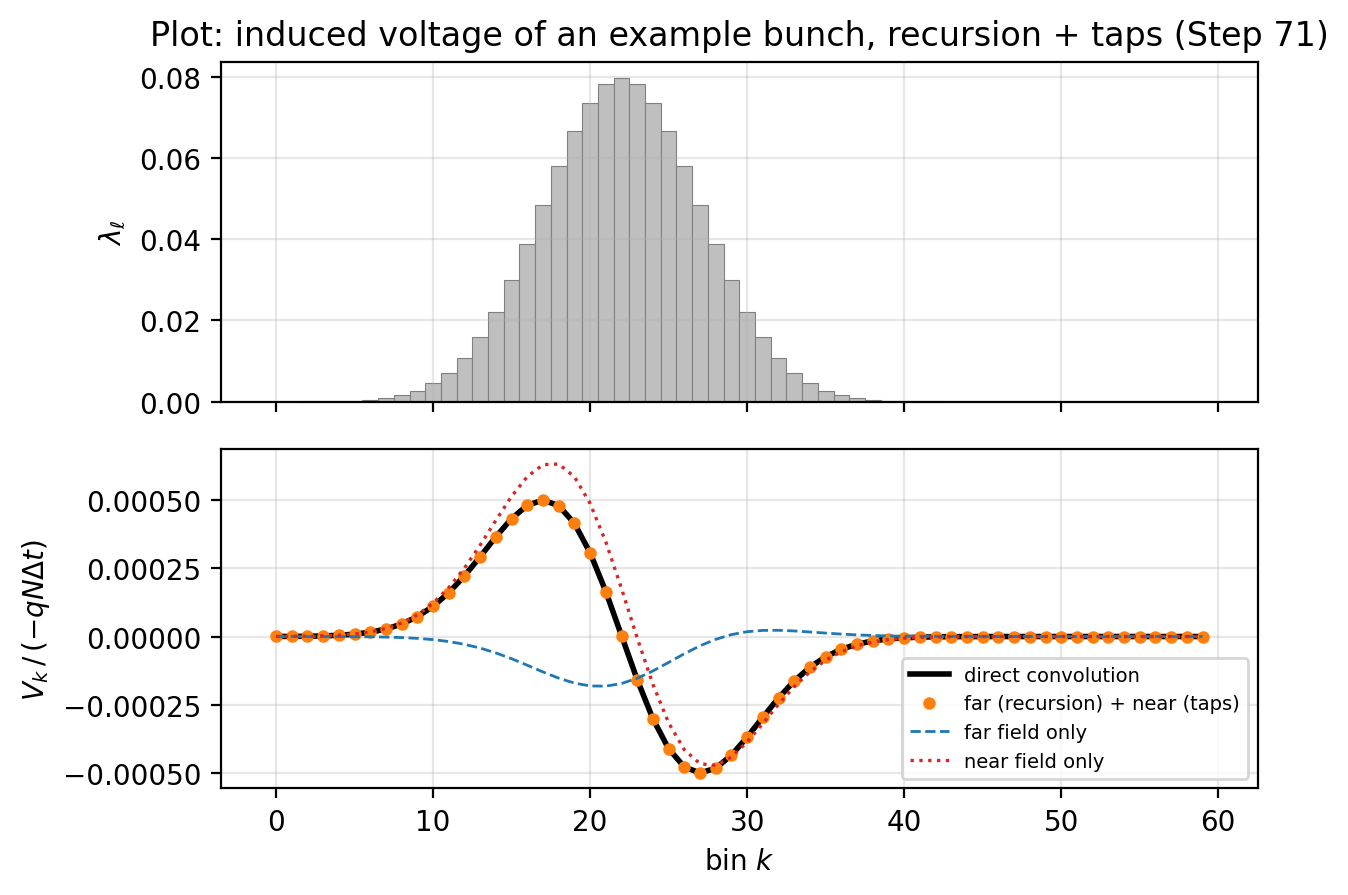

In [ ]:
_M = 60
_k = np.arange(_M)
_lam = np.exp(-0.5 * ((_k - 22) / 5.0) ** 2)
_lam /= _lam.sum()
# recursion + taps (Step 71), one pole pair, prefactor -qN dt set to 1
_z = np.exp(ex_sig)
_rho = ex_r * ((np.exp(ex_sig) - 1) / ex_sig) ** 3 * np.exp(ex_sig / 2)
_taps = {m: float(f_Wt(m)) for m in (-1, 0, 1)}
_lamx = lambda ell: _lam[ell] if 0 <= ell < _M else 0.0
_S, _Vfar, _Vnear = 0j, [], []
for _kk in range(_M):
    _S = _z * _S + _lamx(_kk - 2)
    _Vfar.append(2 * np.real(_rho * _S))
    _Vnear.append(sum(_lamx(_kk - m) * _taps[m] for m in (1, 0, -1)))
_Vfar, _Vnear = np.array(_Vfar), np.array(_Vnear)
# direct discrete convolution with the effective wake, for comparison
_Wn = lambda n: float(f_Wt(n)) if n >= -1 else 0.0
_direct = np.array([sum(_lam[ell] * _Wn(kk - ell) for ell in range(_M)) for kk in range(_M)])
_fig, (_a1, _a2) = plt.subplots(2, 1, figsize=(6.5, 4.6), sharex=True)
_a1.bar(_k, _lam, width=1.0, color="0.75", edgecolor="0.5", lw=0.4)
_a1.set_ylabel(r"$\lambda_\ell$")
_a1.set_title("Plot: induced voltage of an example bunch, recursion + taps (Step 71)")
_a2.plot(_k, _direct, "k", lw=2, label="direct convolution")
_a2.plot(_k, _Vfar + _Vnear, "o", color="C1", ms=3.5, label="far (recursion) + near (taps)")
_a2.plot(_k, _Vfar, "--", color="C0", lw=1, label="far field only")
_a2.plot(_k, _Vnear, ":", color="C3", lw=1.2, label="near field only")
_a2.set_xlabel(r"bin $k$")
_a2.set_ylabel(r"$V_k\, /\, (-qN\Delta t)$")
_a2.legend(loc="lower right", fontsize=7)
for _a in (_a1, _a2):
    _a.grid(alpha=0.3)
_fig.tight_layout()
_fig